In [16]:
from pathlib import Path

accad_dir=Path("/home/sharif/projects/human-motion-latent-directions/data/raw/ACCAD")
walking=[item for item in accad_dir.iterdir() if item.is_dir() and "Walking" in item.name ]

for item in walking:
    print(item.name)

    




Male2Walking_c3d
Female1Walking_c3d
Male1Walking_c3d


In [17]:
from collections import Counter
import pandas as pd

inventory = []

for folder in sorted(walking):

    # Find all files, including files in nested folders
    files = sorted(p for p in folder.rglob("*") if p.is_file())

    # Count file extensions
    extensions = Counter(
        file.suffix.lower() for file in files
    )

    print(f"\nCollection: {folder.name}")
    print(f"Total files: {len(files)}")
    print(f"File types: {dict(extensions)}")

    for file in files:
        inventory.append({
            "collection": folder.name,
            "filename": file.name,
            "extension": file.suffix.lower(),
            "size_MB": round(file.stat().st_size / (1024**2), 3)
        })


# Create a DataFrame
inventory_df = pd.DataFrame(inventory)

display(inventory_df)

print("Total files across all walking collections:",
      len(inventory_df))
    



Collection: Female1Walking_c3d
Total files: 28
File types: {'.npz': 28}

Collection: Male1Walking_c3d
Total files: 10
File types: {'.npz': 10}

Collection: Male2Walking_c3d
Total files: 23
File types: {'.npz': 23}


,collection,filename,extension,size_MB
0,Female1Walking_c3d,B1 - stand to walk_poses.npz,.npz,0.953
1,Female1Walking_c3d,B10 - walk turn left (45)_poses.npz,.npz,1.212
2,Female1Walking_c3d,B11 - walk turn left (135)_poses.npz,.npz,1.432
3,Female1Walking_c3d,B12 - walk turn right (90)_poses.npz,.npz,1.188
4,Female1Walking_c3d,B13 - walk turn right (45)_poses.npz,.npz,1.272
...,...,...,...,...
56,Male2Walking_c3d,B26 - walk to skip_poses.npz,.npz,0.900
57,Male2Walking_c3d,B27 - skip to walk a_poses.npz,.npz,0.700
58,Male2Walking_c3d,B4 - Stand to Walk backwards_poses.npz,.npz,0.706
59,Male2Walking_c3d,B5 - Walk backwards_poses.npz,.npz,1.244


Total files across all walking collections: 61


In [18]:
import numpy as np
exclude = ["turn", "backward", "backwards", "skip",
           "stand", "jump", "hop", "run"]

candidates = []

for folder in walking:
    for file in sorted(folder.rglob("*_poses.npz")):
        name = file.stem.lower()

        if "walk" in name and not any(word in name for word in exclude):
            candidates.append(file)

print(candidates[0])
print("toatl file in len:",len(candidates))

if not candidates:
    raise ValueError("No suitable walking recording found.")

sample_file=candidates[5]

with np.load(sample_file, allow_pickle=True) as data:

    print("\nAvailable arrays:", data.files)

    print("\nArray information:")

    for key in data.files:
        arr=data[key]
        print(f"\n{key}")
        print("Shape:", arr.shape)
        print("Data type:", arr.dtype)
        if arr.size == 1:
            print("Value:", arr.item())

        if "poses" in data:
            num_frames = data["poses"].shape[0]
        print("\nNumber of frames:", num_frames)

        # Check recording frame rate
        if "mocap_framerate" in data:
            fps = float(np.asarray(data["mocap_framerate"]).squeeze())
    
            print("Frame rate:", fps, "FPS")
    
            if "poses" in data:
                print("Approximate duration:", round(num_frames / fps, 2), "seconds")

         


/home/sharif/projects/human-motion-latent-directions/data/raw/ACCAD/Male2Walking_c3d/B18 -  Walk to leap to walk t2_poses.npz
toatl file in len: 20

Available arrays: ['trans', 'gender', 'mocap_framerate', 'betas', 'dmpls', 'poses']

Array information:

trans
Shape: (666, 3)
Data type: float64

Number of frames: 666
Frame rate: 120.0 FPS
Approximate duration: 5.55 seconds

gender
Shape: ()
Data type: <U4
Value: male

Number of frames: 666
Frame rate: 120.0 FPS
Approximate duration: 5.55 seconds

mocap_framerate
Shape: ()
Data type: float64
Value: 120.0

Number of frames: 666
Frame rate: 120.0 FPS
Approximate duration: 5.55 seconds

betas
Shape: (16,)
Data type: float64

Number of frames: 666
Frame rate: 120.0 FPS
Approximate duration: 5.55 seconds

dmpls
Shape: (666, 8)
Data type: float64

Number of frames: 666
Frame rate: 120.0 FPS
Approximate duration: 5.55 seconds

poses
Shape: (666, 156)
Data type: float64

Number of frames: 666
Frame rate: 120.0 FPS
Approximate duration: 5.55 seco

MOTION DATASET: FILE INFORMATION
File: B21 -  put down box to walk a_poses.npz
Gender: male
Frame rate: 120.0 FPS
Number of frames: 666
Duration: 5.55 seconds
Number of joints: 52

ARRAY INFORMATION
------------------------------------------------------------
trans      Shape: (666, 3)        Data type: float64
poses      Shape: (666, 156)      Data type: float64
betas      Shape: (16,)           Data type: float64
dmpls      Shape: (666, 8)        Data type: float64

Other metadata:
Gender: male
Mocap frame rate: 120.0


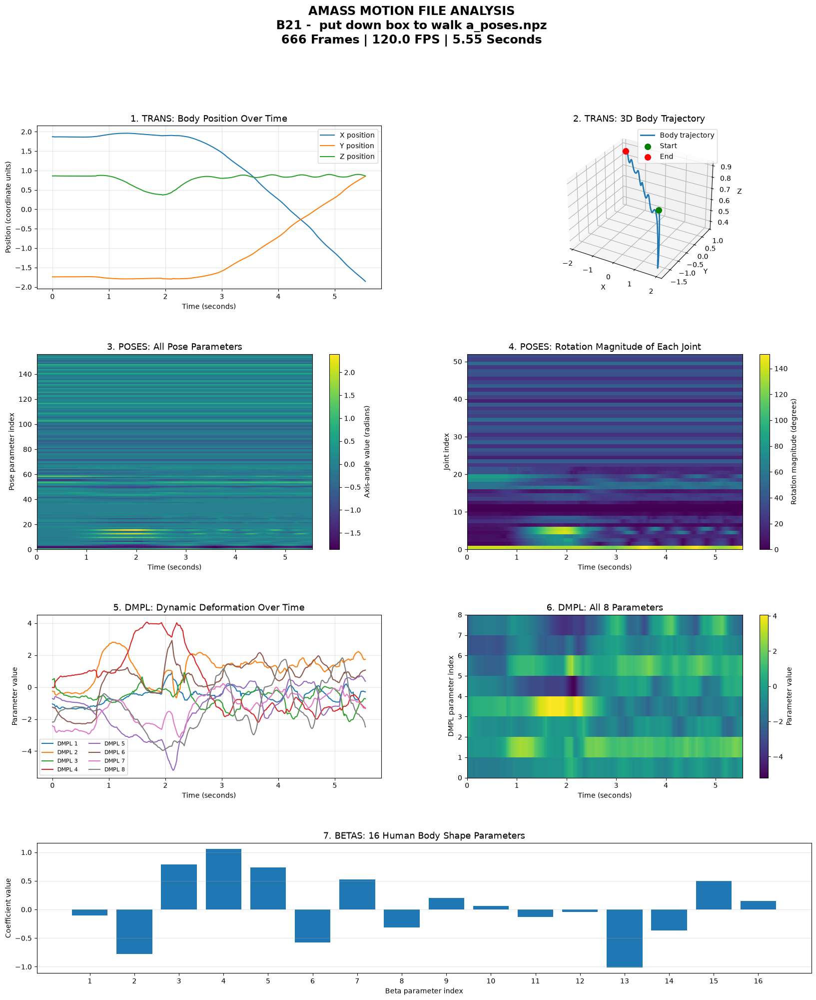

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. LOAD THE SELECTED MOTION FILE
# ==========================================

with np.load(sample_file, allow_pickle=True) as data:

    trans = data["trans"].copy()
    poses = data["poses"].copy()
    betas = data["betas"].copy()
    dmpls = data["dmpls"].copy()

    gender = np.asarray(data["gender"]).item()
    fps = float(np.asarray(data["mocap_framerate"]).squeeze())

n_frames = poses.shape[0]
duration = n_frames / fps
time = np.arange(n_frames) / fps

n_joints = poses.shape[1] // 3

# Reshape poses into frames x joints x 3 rotation components
pose_reshaped = poses.reshape(n_frames, n_joints, 3)

# Calculate rotation magnitude for every joint and frame
rotation_magnitude = np.linalg.norm(pose_reshaped, axis=2)
rotation_degrees = np.degrees(rotation_magnitude)


# ==========================================
# 2. PRINT FILE INFORMATION
# ==========================================

print("=" * 60)
print("MOTION DATASET: FILE INFORMATION")
print("=" * 60)

print("File:", sample_file.name)
print("Gender:", gender)
print("Frame rate:", fps, "FPS")
print("Number of frames:", n_frames)
print("Duration:", round(duration, 2), "seconds")
print("Number of joints:", n_joints)

print("\nARRAY INFORMATION")
print("-" * 60)

arrays = {
    "trans": trans,
    "poses": poses,
    "betas": betas,
    "dmpls": dmpls
}

for name, arr in arrays.items():
    print(f"{name:10} Shape: {str(arr.shape):15} Data type: {arr.dtype}")

print("\nOther metadata:")
print("Gender:", gender)
print("Mocap frame rate:", fps)


# ==========================================
# 3. CREATE THE VISUALIZATION DASHBOARD
# ==========================================

fig = plt.figure(figsize=(20, 22))

gs = fig.add_gridspec(
    4, 2,
    height_ratios=[1, 1.2, 1, 0.8],
    hspace=0.4,
    wspace=0.25
)

fig.suptitle(
    f"AMASS MOTION FILE ANALYSIS\n"
    f"{sample_file.name}\n"
    f"{n_frames} Frames | {fps} FPS | {duration:.2f} Seconds",
    fontsize=17,
    fontweight="bold",
    y=0.99
)


# ==========================================
# PLOT 1: TRANS - BODY POSITION OVER TIME
# ==========================================

ax1 = fig.add_subplot(gs[0, 0])

coordinate_names = ["X", "Y", "Z"]

for i in range(3):
    ax1.plot(
        time,
        trans[:, i],
        label=f"{coordinate_names[i]} position"
    )

ax1.set_title("1. TRANS: Body Position Over Time", fontsize=13)
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("Position (coordinate units)")
ax1.legend()
ax1.grid(True, alpha=0.3)


# ==========================================
# PLOT 2: TRANS - 3D MOVEMENT TRAJECTORY
# ==========================================

ax2 = fig.add_subplot(gs[0, 1], projection="3d")

ax2.plot(
    trans[:, 0],
    trans[:, 1],
    trans[:, 2],
    linewidth=2,
    label="Body trajectory"
)

ax2.scatter(
    *trans[0],
    color="green",
    s=70,
    label="Start"
)

ax2.scatter(
    *trans[-1],
    color="red",
    s=70,
    label="End"
)

ax2.set_title("2. TRANS: 3D Body Trajectory", fontsize=13)
ax2.set_xlabel("X")
ax2.set_ylabel("Y")
ax2.set_zlabel("Z")
ax2.legend()


# ==========================================
# PLOT 3: POSES - ALL 156 PARAMETERS
# ==========================================

ax3 = fig.add_subplot(gs[1, 0])

im1 = ax3.imshow(
    poses.T,
    aspect="auto",
    origin="lower",
    extent=[time[0], time[-1], 0, poses.shape[1]],
    interpolation="nearest"
)

ax3.set_title("3. POSES: All Pose Parameters", fontsize=13)
ax3.set_xlabel("Time (seconds)")
ax3.set_ylabel("Pose parameter index")

fig.colorbar(
    im1,
    ax=ax3,
    label="Axis-angle value (radians)"
)


# ==========================================
# PLOT 4: POSES - JOINT ROTATION MAGNITUDE
# ==========================================

ax4 = fig.add_subplot(gs[1, 1])

im2 = ax4.imshow(
    rotation_degrees.T,
    aspect="auto",
    origin="lower",
    extent=[time[0], time[-1], 0, n_joints],
    interpolation="nearest"
)

ax4.set_title(
    "4. POSES: Rotation Magnitude of Each Joint",
    fontsize=13
)

ax4.set_xlabel("Time (seconds)")
ax4.set_ylabel("Joint index")

fig.colorbar(
    im2,
    ax=ax4,
    label="Rotation magnitude (degrees)"
)


# ==========================================
# PLOT 5: DMPL - 8 PARAMETERS OVER TIME
# ==========================================

ax5 = fig.add_subplot(gs[2, 0])

for i in range(dmpls.shape[1]):
    ax5.plot(
        time,
        dmpls[:, i],
        label=f"DMPL {i + 1}"
    )

ax5.set_title("5. DMPL: Dynamic Deformation Over Time", fontsize=13)
ax5.set_xlabel("Time (seconds)")
ax5.set_ylabel("Parameter value")
ax5.legend(ncol=2, fontsize=8)
ax5.grid(True, alpha=0.3)


# ==========================================
# PLOT 6: DMPL - HEATMAP
# ==========================================

ax6 = fig.add_subplot(gs[2, 1])

im3 = ax6.imshow(
    dmpls.T,
    aspect="auto",
    origin="lower",
    extent=[time[0], time[-1], 0, dmpls.shape[1]],
    interpolation="nearest"
)

ax6.set_title("6. DMPL: All 8 Parameters", fontsize=13)
ax6.set_xlabel("Time (seconds)")
ax6.set_ylabel("DMPL parameter index")

fig.colorbar(
    im3,
    ax=ax6,
    label="Parameter value"
)


# ==========================================
# PLOT 7: BETAS - BODY SHAPE PARAMETERS
# ==========================================

ax7 = fig.add_subplot(gs[3, :])

ax7.bar(
    np.arange(1, len(betas) + 1),
    betas
)

ax7.set_title("7. BETAS: 16 Human Body Shape Parameters", fontsize=13)
ax7.set_xlabel("Beta parameter index")
ax7.set_ylabel("Coefficient value")
ax7.set_xticks(np.arange(1, len(betas) + 1))
ax7.grid(axis="y", alpha=0.3)


# ==========================================
# 4. DISPLAY EVERYTHING
# ==========================================

plt.show()

In [20]:
import re
import pandas as pd

# Activities we don't want in our initial continuous-walking subset
exclude_terms = {
    "turn", "backward", "backwards",
    "skip", "leap", "jump", "hop",
    "run", "running", "stand", "standing"
}

walk_terms = {"walk", "walking", "walks", "walked"}

results = []

for folder in sorted(walking):

    for file in sorted(folder.rglob("*_poses.npz")):

        # Extract words from filename
        words = set(re.findall(r"[a-z]+", file.stem.lower()))

        has_walk = bool(words & walk_terms)
        excluded = sorted(words & exclude_terms)

        if has_walk and not excluded:
            category = "candidate_continuous_walk"
        elif has_walk and excluded:
            category = "mixed_or_other_walking"
        else:
            category = "not_walking_filename"

        results.append({
            "subject": folder.name,
            "filename": file.name,
            "category": category,
            "excluded_terms": ", ".join(excluded)
        })

# Create report
motion_df = pd.DataFrame(results)

# Show candidate recordings
candidates_df = motion_df[
    motion_df["category"] == "candidate_continuous_walk"
]

print("Candidate continuous-walking recordings:",
      len(candidates_df))

display(candidates_df)

# Show recordings requiring further inspection
review_df = motion_df[
    motion_df["category"] != "candidate_continuous_walk"
]

print("\nOther recordings:", len(review_df))
display(review_df)

# Save complete classification
motion_df.to_csv("accad_motion_classification.csv", index=False)

Candidate continuous-walking recordings: 16


,subject,filename,category,excluded_terms
10,Female1Walking_c3d,B19 - walk to pick up box_poses.npz,candidate_continuous_walk,
13,Female1Walking_c3d,B20 - walk with box_poses.npz,candidate_continuous_walk,
14,Female1Walking_c3d,B21 - put down box to walk_poses.npz,candidate_continuous_walk,
15,Female1Walking_c3d,B21 s2 - put down box to walk_poses.npz,candidate_continuous_walk,
16,Female1Walking_c3d,B21 s3 - put down box to walk_poses.npz,candidate_continuous_walk,
19,Female1Walking_c3d,B24 - walk to crouch_poses.npz,candidate_continuous_walk,
20,Female1Walking_c3d,B25 - crouch to walk1_poses.npz,candidate_continuous_walk,
22,Female1Walking_c3d,B3 - walk1_poses.npz,candidate_continuous_walk,
34,Male1Walking_c3d,Walk B21 - Put Down Box to walk_poses.npz,candidate_continuous_walk,
35,Male1Walking_c3d,Walk B22 - Side step left_poses.npz,candidate_continuous_walk,



Other recordings: 45


,subject,filename,category,excluded_terms
0,Female1Walking_c3d,B1 - stand to walk_poses.npz,mixed_or_other_walking,stand
1,Female1Walking_c3d,B10 - walk turn left (45)_poses.npz,mixed_or_other_walking,turn
2,Female1Walking_c3d,B11 - walk turn left (135)_poses.npz,mixed_or_other_walking,turn
3,Female1Walking_c3d,B12 - walk turn right (90)_poses.npz,mixed_or_other_walking,turn
4,Female1Walking_c3d,B13 - walk turn right (45)_poses.npz,mixed_or_other_walking,turn
5,Female1Walking_c3d,B14 - walk turn right (135)_poses.npz,mixed_or_other_walking,turn
6,Female1Walking_c3d,B15 - walk turn around (same direction)_poses.npz,mixed_or_other_walking,turn
7,Female1Walking_c3d,B16 - walk turn change direction_poses.npz,mixed_or_other_walking,turn
8,Female1Walking_c3d,B17 - walk to hop to walk1_poses.npz,mixed_or_other_walking,hop
9,Female1Walking_c3d,B18 - walk to leap to walk_poses.npz,mixed_or_other_walking,leap


In [21]:
from pathlib import Path

project_dir = Path(
    "/home/sharif/projects/human-motion-latent-directions"
)

body_model_dir = project_dir / "data" / "body_models" / "smplh"

# Create directories for the three body-model variants
for gender in ["male", "female", "neutral"]:
    (body_model_dir / gender).mkdir(parents=True, exist_ok=True)

print("SMPL+H directory structure created.")

for path in sorted(body_model_dir.rglob("*")):
    print(path.relative_to(project_dir))

SMPL+H directory structure created.
data/body_models/smplh/LICENSE.txt
data/body_models/smplh/female
data/body_models/smplh/female/model.npz
data/body_models/smplh/info.txt
data/body_models/smplh/male
data/body_models/smplh/male/model.npz
data/body_models/smplh/neutral
data/body_models/smplh/neutral/model.npz


In [22]:
import tarfile
from pathlib import Path

download_dir = Path.home() / "Downloads"
archive_path = download_dir / "smplh.tar.xz"

print("Archive exists:", archive_path.exists())

if archive_path.exists():

    with tarfile.open(archive_path, "r:xz") as archive:

        members = archive.getnames()

        print("\nTotal archive entries:", len(members))

        print("\nArchive contents:")

        for name in members:
            print(name)

else:
    print("Archive not found in Downloads.")

Archive exists: True

Total archive entries: 8

Archive contents:
female
female/model.npz
info.txt
LICENSE.txt
male
male/model.npz
neutral
neutral/model.npz


In [23]:
import tarfile
import shutil
from pathlib import Path

# Archive location
archive_path = Path.home() / "Downloads" / "smplh.tar.xz"

# Destination
body_model_dir = (
    Path("/home/sharif/projects/human-motion-latent-directions")
    / "data" / "body_models" / "smplh"
)

# Files we need to extract
files_to_extract = [
    "male/model.npz",
    "female/model.npz",
    "neutral/model.npz",
    "info.txt",
    "LICENSE.txt"
]

with tarfile.open(archive_path, "r:xz") as archive:

    for filename in files_to_extract:

        source = archive.extractfile(filename)

        if source is None:
            raise FileNotFoundError(filename)

        destination = body_model_dir / filename
        destination.parent.mkdir(parents=True, exist_ok=True)

        with source, destination.open("wb") as output:
            shutil.copyfileobj(source, output)

        print("Extracted:", destination.relative_to(body_model_dir))

print("\nSMPL+H extraction completed!")

Extracted: male/model.npz
Extracted: female/model.npz
Extracted: neutral/model.npz
Extracted: info.txt
Extracted: LICENSE.txt

SMPL+H extraction completed!


In [24]:
import numpy as np
from pathlib import Path

body_model_dir = Path(
    "/home/sharif/projects/human-motion-latent-directions/data/body_models/smplh"
)

for gender in ["male", "female", "neutral"]:

    model_path = body_model_dir / gender / "model.npz"

    print(f"\n{'='*45}")
    print("Model:", gender)
    print("File exists:", model_path.exists())

    if not model_path.exists():
        continue

    print("File size:", round(model_path.stat().st_size / (1024**2), 2), "MB")

    with np.load(model_path, allow_pickle=True) as model:

        print("Available parameters:")

        for key in model.files:
            arr = model[key]
            print(f"{key:25} Shape: {arr.shape}, Type: {arr.dtype}")


Model: male
File exists: True
File size: 83.22 MB
Available parameters:
J_regressor_prior         Shape: (24, 6890), Type: float64
f                         Shape: (13776, 3), Type: uint32
J_regressor               Shape: (52, 6890), Type: float64
kintree_table             Shape: (2, 52), Type: int64
J                         Shape: (24, 3), Type: float64
weights_prior             Shape: (6890, 24), Type: float64
weights                   Shape: (6890, 52), Type: float64
posedirs                  Shape: (6890, 3, 459), Type: float64
bs_style                  Shape: (), Type: |S3
v_template                Shape: (6890, 3), Type: float64
shapedirs                 Shape: (6890, 3, 16), Type: float64
bs_type                   Shape: (), Type: |S7

Model: female
File exists: True
File size: 83.22 MB
Available parameters:
J_regressor_prior         Shape: (24, 6890), Type: float64
f                         Shape: (13776, 3), Type: uint32
J_regressor               Shape: (52, 6890), Type: flo

In [25]:
import numpy as np
from pathlib import Path

motion_path = Path(
    "/home/sharif/projects/human-motion-latent-directions/data/raw/ACCAD/"
    "Female1Walking_c3d/B3 - walk1_poses.npz"
)

with np.load(motion_path, allow_pickle=True) as data:
    print("Available keys:", list(data.keys()))
    print()
    print("poses shape:", data["poses"].shape)   # (frames, 156)
    print("trans shape:", data["trans"].shape)   # (frames, 3)
    print("betas shape:", data["betas"].shape)   # (16,) or (1, 16)
    print()
    n_frames = data["poses"].shape[0]
    fps = float(data["mocap_frame_rate"]) if "mocap_frame_rate" in data else None
    duration = float(data["mocap_time_length"]) if "mocap_time_length" in data else None
    print("Number of frames:", n_frames)
    print("FPS:", fps)
    print("Duration (s):", duration)
    if fps:
        print("Computed duration from frames/FPS:", n_frames / fps)

Available keys: ['trans', 'gender', 'mocap_framerate', 'betas', 'dmpls', 'poses']

poses shape: (915, 156)
trans shape: (915, 3)
betas shape: (16,)

Number of frames: 915
FPS: None
Duration (s): None


Frames: 915, FPS: 120.0, Duration: 7.62s


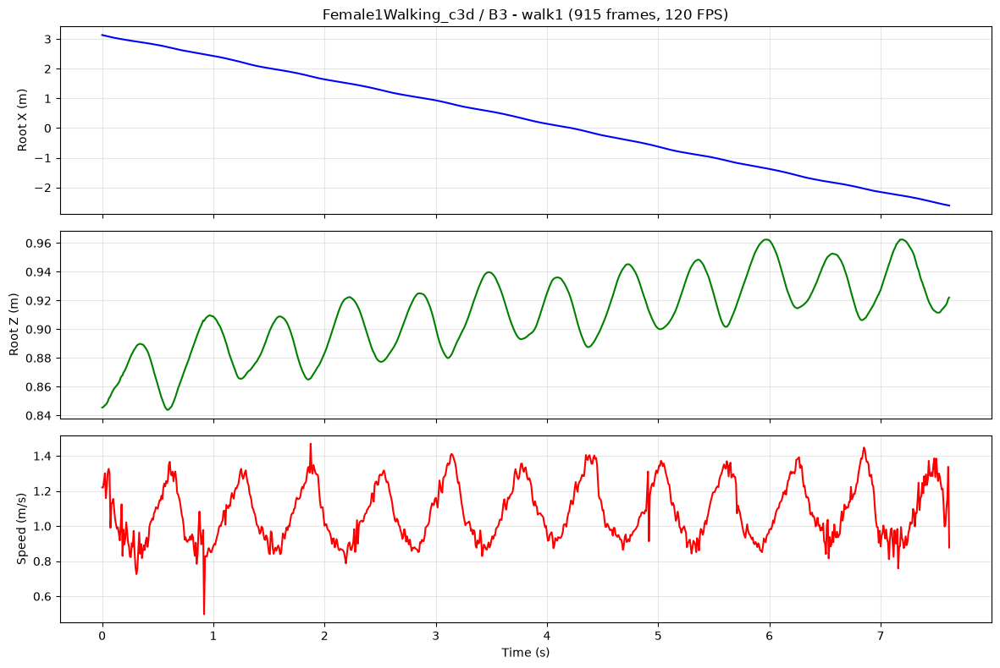


Speed stats:
  Mean: 1.079 m/s
  Min:  0.497 m/s
  Max:  1.469 m/s


In [26]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ─── Load the data ────────────────────────────────────────────────
motion_path = Path(
    "/home/sharif/projects/human-motion-latent-directions/data/raw/ACCAD/"
    "Female1Walking_c3d/B3 - walk1_poses.npz"
)

with np.load(motion_path, allow_pickle=True) as data:
    poses  = data["poses"]   # (915, 156)
    trans  = data["trans"]   # (915, 3)
    betas  = data["betas"]   # (16,)

    # Handle the actual key name used in this file
    fps = float(data["mocap_framerate"]) if "mocap_framerate" in data else 120.0
    n_frames = poses.shape[0]

print(f"Frames: {n_frames}, FPS: {fps}, Duration: {n_frames/fps:.2f}s")

# ─── Reconstruct root trajectory (3D positions) ──────────────────
# trans is root translation in meters — use it directly as root position
root_x = trans[:, 0]   # forward
root_y = trans[:, 1]   # up
root_z = trans[:, 2]   # lateral

# ─── Compute root speed ──────────────────────────────────────────
# speed[t] = distance between consecutive root positions × FPS
dt = 1.0 / fps
root_speed = np.zeros(n_frames)
root_speed[1:] = np.sqrt(
    (root_x[1:] - root_x[:-1])**2 +
    (root_y[1:] - root_y[:-1])**2 +
    (root_z[1:] - root_z[:-1])**2
) / dt
root_speed[0] = root_speed[1]  # first frame = same as second

# ─── Time axis ───────────────────────────────────────────────────
time = np.arange(n_frames) / fps

# ─── Plot ────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

axes[0].plot(time, root_x, 'b-', linewidth=1.5)
axes[0].set_ylabel('Root X (m)')
axes[0].set_title('Female1Walking_c3d / B3 - walk1 (915 frames, {:.0f} FPS)'.format(fps))
axes[0].grid(True, alpha=0.3)

axes[1].plot(time, root_z, 'g-', linewidth=1.5)
axes[1].set_ylabel('Root Z (m)')
axes[1].grid(True, alpha=0.3)

axes[2].plot(time, root_speed, 'r-', linewidth=1.5)
axes[2].set_xlabel('Time (s)')
axes[2].set_ylabel('Speed (m/s)')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('root_trajectory_visualization.png', dpi=150)
plt.show()

# ─── Summary stats ──────────────────────────────────────────────
print(f"\nSpeed stats:")
print(f"  Mean: {root_speed.mean():.3f} m/s")
print(f"  Min:  {root_speed.min():.3f} m/s")
print(f"  Max:  {root_speed.max():.3f} m/s")

In [27]:
import inspect
import human_body_prior.body_model.body_model as bm_module

# Save the original LBS function
original_lbs = bm_module.lbs

print("Original function:", original_lbs.__module__)
print("Original signature:", inspect.signature(original_lbs))

# Remove the unsupported dtype keyword when calling SMPL-X
def compatible_lbs(*args, dtype=None, **kwargs):
    return original_lbs(*args, **kwargs)

bm_module.lbs = compatible_lbs

print("\nCompatibility patch applied!")

Original function: __main__
Original signature: (*args, dtype=None, **kwargs)

Compatibility patch applied!


In [28]:
import numpy as np
import torch
from pathlib import Path
from human_body_prior.body_model.body_model import BodyModel

# 1. Define paths
project_dir = Path(
    "/home/sharif/projects/human-motion-latent-directions"
)

motion_path = (
    project_dir / "data/raw/ACCAD/Female1Walking_c3d/"
    "B3 - walk1_poses.npz"
)

model_path = (
    project_dir / "data/body_models/smplh/female/model.npz"
)

# 2. Load one motion frame
with np.load(motion_path, allow_pickle=True) as data:

    poses = data["poses"].astype(np.float32)
    trans = data["trans"].astype(np.float32)
    betas = data["betas"].astype(np.float32)

    # Select the first frame
    frame_pose = poses[0:1]

    frame_trans = trans[0:1]

    frame_betas = betas[:16][None, :]

# 3. Load female SMPL+H model
body_model = BodyModel(
    bm_path=str(model_path),
    model_type="smplh",
    num_betas=16
)

body_model.eval()

# 4. Separate the 156 pose parameters
root_orient = torch.from_numpy(frame_pose[:, :3])
pose_body = torch.from_numpy(frame_pose[:, 3:66])
pose_hand = torch.from_numpy(frame_pose[:, 66:156])

# 5. Reconstruct the body
with torch.no_grad():

    output = body_model(
        root_orient=root_orient,
        pose_body=pose_body,
        pose_hand=pose_hand,
        betas=torch.from_numpy(frame_betas),
        trans=torch.from_numpy(frame_trans)
    )

# 6. Extract 3D joints and vertices
joints_3d = output.Jtr.cpu().numpy()
vertices_3d = output.v.cpu().numpy()

print("Reconstruction successful!")

print("3D joints shape:", joints_3d.shape)
print("Body vertices shape:", vertices_3d.shape)

print("All joints finite:", np.isfinite(joints_3d).all())
print("All vertices finite:", np.isfinite(vertices_3d).all())

Reconstruction successful!
3D joints shape: (1, 52, 3)
Body vertices shape: (1, 6890, 3)
All joints finite: True
All vertices finite: True


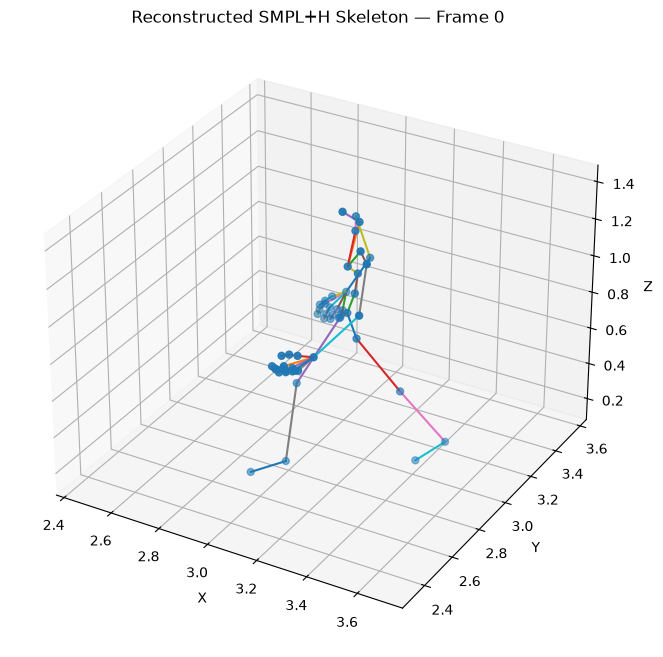

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Get joint coordinates from the reconstructed frame
joints = joints_3d[0]

# Load the skeletal hierarchy
with np.load(model_path, allow_pickle=True) as model:
    kintree = model["kintree_table"]

parents = kintree[0].astype(int)
joint_ids = kintree[1].astype(int)

# Map joint IDs to their array indices
joint_map = {
    joint_id: idx
    for idx, joint_id in enumerate(joint_ids)
}

# Create skeletal connections
edges = []

for child_idx, parent_id in enumerate(parents):
    parent_idx = joint_map.get(parent_id)

    if parent_idx is not None:
        edges.append((parent_idx, child_idx))

# Visualize skeleton
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

# Plot joints
ax.scatter(
    joints[:, 0],
    joints[:, 1],
    joints[:, 2],
    s=25
)

# Connect joints according to skeletal hierarchy
for parent, child in edges:
    ax.plot(
        [joints[parent, 0], joints[child, 0]],
        [joints[parent, 1], joints[child, 1]],
        [joints[parent, 2], joints[child, 2]]
    )

# Equal axis scaling
center = joints.mean(axis=0)
radius = max(np.ptp(joints, axis=0)) / 2

ax.set_xlim(center[0] - radius, center[0] + radius)
ax.set_ylim(center[1] - radius, center[1] + radius)
ax.set_zlim(center[2] - radius, center[2] + radius)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")

ax.set_title("Reconstructed SMPL+H Skeleton — Frame 0")

plt.show()

In [30]:
import numpy as np
import torch
from pathlib import Path

# Reapply the LBS compatibility fix for this session
import human_body_prior.body_model.body_model as bm_module
from smplx.lbs import lbs as smplx_lbs

def compatible_lbs(*args, dtype=None, **kwargs):
    return smplx_lbs(*args, **kwargs)

bm_module.lbs = compatible_lbs

from human_body_prior.body_model.body_model import BodyModel

# Paths
project_dir = Path(
    "/home/sharif/projects/human-motion-latent-directions"
)

motion_path = (
    project_dir / "data/raw/ACCAD/Female1Walking_c3d/"
    "B3 - walk1_poses.npz"
)

model_path = (
    project_dir / "data/body_models/smplh/female/model.npz"
)

# Load motion data
with np.load(motion_path, allow_pickle=True) as data:
    poses = data["poses"].astype(np.float32)
    trans = data["trans"].astype(np.float32)
    betas = data["betas"].astype(np.float32)
    fps = float(np.asarray(data["mocap_framerate"]).squeeze())

num_frames = poses.shape[0]

print("Frames:", num_frames)
print("FPS:", fps)
print("Duration:", num_frames / fps, "seconds")

# Load body model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

body_model = BodyModel(
    bm_path=str(model_path),
    model_type="smplh",
    num_betas=16
).to(device)

body_model.eval()

# Reconstruct all frames in batches
all_joints = []

batch_size = 32

with torch.no_grad():

    for start in range(0, num_frames, batch_size):

        end = min(start + batch_size, num_frames)

        pose_batch = torch.from_numpy(
            poses[start:end]
        ).to(device)

        trans_batch = torch.from_numpy(
            trans[start:end]
        ).to(device)

        batch_betas = torch.from_numpy(
            np.repeat(
                betas[:16][None, :],
                end - start,
                axis=0
            )
        ).to(device)

        output = body_model(
            root_orient=pose_batch[:, :3],
            pose_body=pose_batch[:, 3:66],
            pose_hand=pose_batch[:, 66:156],
            betas=batch_betas,
            trans=trans_batch
        )

        joints = output.Jtr.cpu().numpy()

        all_joints.append(joints)

        print(f"Processed frames {start}–{end - 1}")

# Combine all batches
joints_all = np.concatenate(all_joints, axis=0)

print("\nReconstruction complete!")
print("Joint sequence shape:", joints_all.shape)
print("All values finite:", np.isfinite(joints_all).all())

Frames: 915
FPS: 120.0
Duration: 7.625 seconds
Processed frames 0–31
Processed frames 32–63
Processed frames 64–95
Processed frames 96–127
Processed frames 128–159
Processed frames 160–191
Processed frames 192–223
Processed frames 224–255
Processed frames 256–287
Processed frames 288–319
Processed frames 320–351
Processed frames 352–383
Processed frames 384–415
Processed frames 416–447
Processed frames 448–479
Processed frames 480–511
Processed frames 512–543
Processed frames 544–575
Processed frames 576–607
Processed frames 608–639
Processed frames 640–671
Processed frames 672–703
Processed frames 704–735
Processed frames 736–767
Processed frames 768–799
Processed frames 800–831
Processed frames 832–863
Processed frames 864–895
Processed frames 896–914

Reconstruction complete!
Joint sequence shape: (915, 52, 3)
All values finite: True


In [31]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Load skeletal hierarchy
with np.load(model_path, allow_pickle=True) as model:
    kintree = model["kintree_table"]

parents = kintree[0].astype(int)
joint_ids = kintree[1].astype(int)

joint_map = {
    joint_id: idx
    for idx, joint_id in enumerate(joint_ids)
}

edges = []

for child_idx, parent_id in enumerate(parents):
    parent_idx = joint_map.get(parent_id)

    if parent_idx is not None and parent_idx != child_idx:
        edges.append((parent_idx, child_idx))

# Display every 4th frame (approximately 30 FPS)
frame_step = max(1, round(fps / 30))

frame_indices = list(range(0, num_frames, frame_step))

if frame_indices[-1] != num_frames - 1:
    frame_indices.append(num_frames - 1)

# Create figure
fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

# Consistent axis limits across the animation
minimum = joints_all.min(axis=(0, 1))
maximum = joints_all.max(axis=(0, 1))

center = (minimum + maximum) / 2
radius = max((maximum - minimum)) / 2 * 1.1

ax.set_xlim(center[0] - radius, center[0] + radius)
ax.set_ylim(center[1] - radius, center[1] + radius)
ax.set_zlim(center[2] - radius, center[2] + radius)

ax.set_box_aspect((1, 1, 1))

# Initial frame
initial = joints_all[0]

scatter = ax.scatter(
    initial[:, 0],
    initial[:, 1],
    initial[:, 2],
    s=20
)

lines = []

for parent, child in edges:
    line, = ax.plot(
        [initial[parent, 0], initial[child, 0]],
        [initial[parent, 1], initial[child, 1]],
        [initial[parent, 2], initial[child, 2]]
    )
    lines.append(line)

def update(frame_number):

    frame = joints_all[frame_indices[frame_number]]

    scatter._offsets3d = (
        frame[:, 0],
        frame[:, 1],
        frame[:, 2]
    )

    for line, (parent, child) in zip(lines, edges):

        line.set_data(
            [frame[parent, 0], frame[child, 0]],
            [frame[parent, 1], frame[child, 1]]
        )

        line.set_3d_properties(
            [frame[parent, 2], frame[child, 2]]
        )

    original_frame = frame_indices[frame_number]

    ax.set_title(
        f"ACCAD Female1 Walking | "
        f"Frame {original_frame}/{num_frames - 1} | "
        f"Time: {original_frame / fps:.2f}s"
    )

    return [scatter] + lines

animation = FuncAnimation(
    fig,
    update,
    frames=len(frame_indices),
    interval=1000 / 30,
    blit=False
)

plt.close(fig)

display(HTML(animation.to_jshtml()))

Animation size has reached 20971691 bytes, exceeding the limit of 20971520.0. If you're sure you want a larger animation embedded, set the animation.embed_limit rc parameter to a larger value (in MB). This and further frames will be dropped.


Root translation shape: (915, 3)
X: min=-2.6087, max=3.1348, range=5.7435
Y: min=-2.4888, max=3.2074, range=5.6963
Z: min=0.8438, max=0.9626, range=0.1187


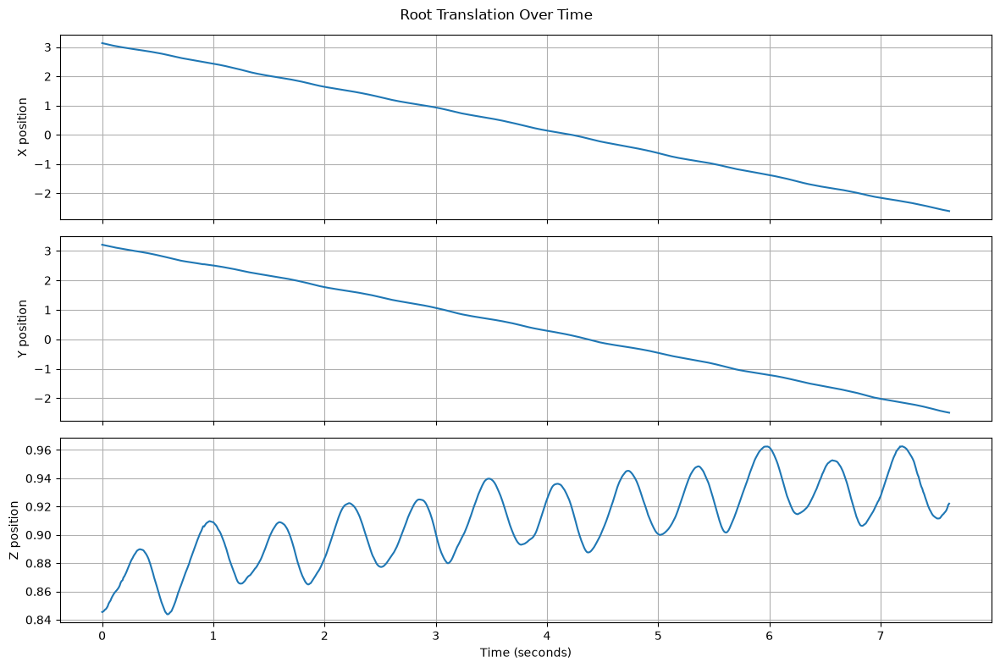

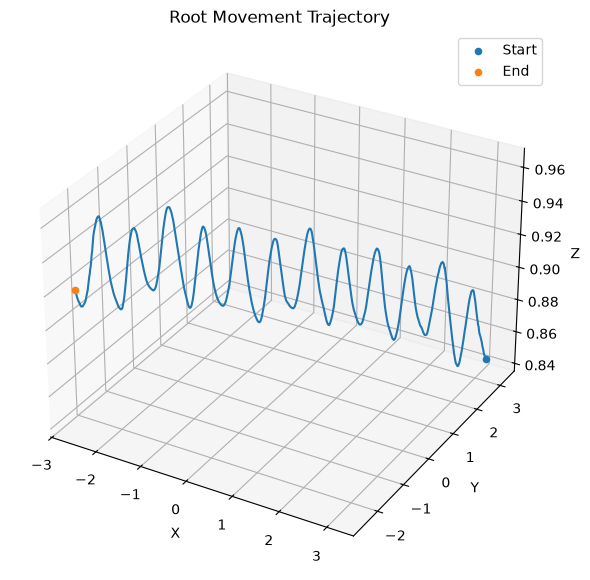

3D path length: 8.217041
3D net displacement: 8.089561
Recording duration: 7.616666666666666 seconds


In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Load root translation
with np.load(motion_path, allow_pickle=True) as data:
    trans = data["trans"].astype(np.float32)
    fps = float(np.asarray(data["mocap_framerate"]).squeeze())

# Create time axis
time = np.arange(len(trans)) / fps

# Inspect coordinate ranges
print("Root translation shape:", trans.shape)

for i, axis in enumerate(["X", "Y", "Z"]):
    print(
        f"{axis}: min={trans[:, i].min():.4f}, "
        f"max={trans[:, i].max():.4f}, "
        f"range={np.ptp(trans[:, i]):.4f}"
    )

# Plot coordinate movement over time
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)

for i, axis in enumerate(["X", "Y", "Z"]):
    axes[i].plot(time, trans[:, i])
    axes[i].set_ylabel(f"{axis} position")
    axes[i].grid(True)

axes[-1].set_xlabel("Time (seconds)")
fig.suptitle("Root Translation Over Time")
plt.tight_layout()
plt.show()

# Plot 3D trajectory
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot(trans[:, 0], trans[:, 1], trans[:, 2])
ax.scatter(*trans[0], label="Start")
ax.scatter(*trans[-1], label="End")

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Root Movement Trajectory")
ax.legend()

plt.show()

# Calculate preliminary 3D displacement
differences = np.diff(trans, axis=0)

path_length_3d = np.linalg.norm(differences, axis=1).sum()
net_displacement_3d = np.linalg.norm(trans[-1] - trans[0])

print("3D path length:", path_length_3d)
print("3D net displacement:", net_displacement_3d)
print("Recording duration:", time[-1], "seconds")

Analyzing: B3 - walk1_poses.npz

WALKING SPEED ANALYSIS
----------------------------------------
Duration: 7.62 seconds
Horizontal distance: 8.106 m
Net displacement: 8.089 m
Average path speed: 1.064 m/s
Average net speed: 1.062 m/s

Instantaneous speed statistics:
Minimum: 0.497 m/s
Median: 1.030 m/s
Maximum: 1.469 m/s


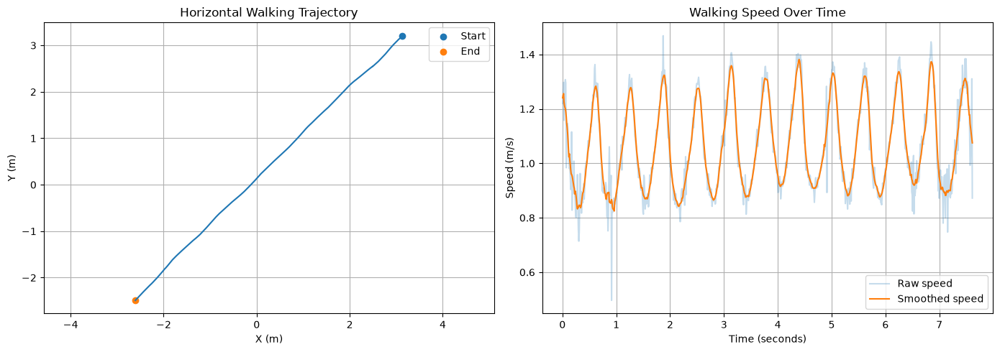

In [33]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Load root translation and FPS
with np.load(motion_path, allow_pickle=True) as data:
    trans = data["trans"].astype(np.float64)
    fps = float(np.asarray(data["mocap_framerate"]).squeeze())

print("Analyzing:", motion_path.name)

# Extract horizontal coordinates (X, Y)
xy = trans[:, :2]

# Calculate frame-to-frame displacement
displacement = np.diff(xy, axis=0)

# Distance travelled between consecutive frames
step_distance = np.linalg.norm(displacement, axis=1)

# Instantaneous horizontal speed
instant_speed = step_distance * fps

# Total recording duration
duration = (len(trans) - 1) / fps

# Total horizontal path length
horizontal_distance = step_distance.sum()

# Straight-line horizontal displacement
net_displacement = np.linalg.norm(xy[-1] - xy[0])

# Average speeds
average_path_speed = horizontal_distance / duration
average_net_speed = net_displacement / duration

print("\nWALKING SPEED ANALYSIS")
print("-" * 40)

print(f"Duration: {duration:.2f} seconds")
print(f"Horizontal distance: {horizontal_distance:.3f} m")
print(f"Net displacement: {net_displacement:.3f} m")
print(f"Average path speed: {average_path_speed:.3f} m/s")
print(f"Average net speed: {average_net_speed:.3f} m/s")

print("\nInstantaneous speed statistics:")
print(f"Minimum: {instant_speed.min():.3f} m/s")
print(f"Median: {np.median(instant_speed):.3f} m/s")
print(f"Maximum: {instant_speed.max():.3f} m/s")

# Smooth speed for visualization (100 ms window)
window = max(1, round(fps * 0.1))

smooth_speed = (
    pd.Series(instant_speed)
    .rolling(window=window, center=True, min_periods=1)
    .mean()
)

time_speed = (np.arange(len(instant_speed)) + 0.5) / fps

# Visualize trajectory and speed
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(xy[:, 0], xy[:, 1])
axes[0].scatter(*xy[0], label="Start")
axes[0].scatter(*xy[-1], label="End")
axes[0].set_xlabel("X (m)")
axes[0].set_ylabel("Y (m)")
axes[0].set_title("Horizontal Walking Trajectory")
axes[0].legend()
axes[0].axis("equal")
axes[0].grid(True)

axes[1].plot(time_speed, instant_speed, alpha=0.25, label="Raw speed")
axes[1].plot(time_speed, smooth_speed, label="Smoothed speed")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Speed (m/s)")
axes[1].set_title("Walking Speed Over Time")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [34]:
import numpy as np
import pandas as pd
from pathlib import Path

# Verify reconstructed motion
assert len(joints_all) == len(poses), (
    "Reconstructed joints and pose frames do not match. "
    "Run the full reconstruction cell again."
)

# Window configuration
window_seconds = 2
overlap_seconds = 1

window_frames = int(window_seconds * fps)
stride = int((window_seconds - overlap_seconds) * fps)

num_frames = len(poses)

# Generate window starting frames
starts = list(range(0, num_frames - window_frames + 1, stride))

# Include the final frames if not already covered
last_start = num_frames - window_frames

if starts[-1] != last_start:
    starts.append(last_start)

# Output directory
output_dir = (
    project_dir / "data/processed/prototype/windows"
)

output_dir.mkdir(parents=True, exist_ok=True)

records = []

for i, start in enumerate(starts):

    end = start + window_frames

    # Extract window data
    pose_window = poses[start:end]
    trans_window = trans[start:end]
    joints_window = joints_all[start:end]

    # Root-relative joints (joint 0 is the pelvis)
    relative_joints = (
        joints_window - joints_window[:, 0:1, :]
    )

    # Calculate horizontal walking speed
    xy = trans_window[:, :2]

    distances = np.linalg.norm(
        np.diff(xy, axis=0), axis=1
    )

    path_length = distances.sum()

    duration = (window_frames - 1) / fps

    avg_speed = path_length / duration

    net_displacement = np.linalg.norm(
        xy[-1] - xy[0]
    )

    # Save individual sample
    sample_name = f"sample_{i+1:03d}.npz"

    np.savez_compressed(
        output_dir / sample_name,
        poses=pose_window,
        trans=trans_window,
        joints=joints_window,
        joints_root_relative=relative_joints,
        fps=np.float32(fps),
        speed_xy_units_per_s=np.float32(avg_speed),
        source_file=np.array(motion_path.name),
        start_frame=np.int32(start),
        end_frame_exclusive=np.int32(end)
    )

    records.append({
        "sample": sample_name,
        "subject": motion_path.parent.name,
        "source_file": motion_path.name,
        "start_frame": start,
        "end_frame": end,
        "frames": window_frames,
        "duration_seconds": round(duration, 4),
        "speed_xy_units_per_s": round(avg_speed, 4),
        "path_length": round(path_length, 4),
        "net_displacement": round(net_displacement, 4)
    })

# Create manifest
manifest = pd.DataFrame(records)

manifest.to_csv(
    output_dir / "window_manifest.csv",
    index=False
)

display(manifest)

print("\nTotal motion windows:", len(manifest))
print("Saved to:", output_dir)

,sample,subject,source_file,start_frame,end_frame,frames,duration_seconds,speed_xy_units_per_s,path_length,net_displacement
0,sample_001.npz,Female1Walking_c3d,B3 - walk1_poses.npz,0,240,240,1.9917,1.0412,2.0738,2.0655
1,sample_002.npz,Female1Walking_c3d,B3 - walk1_poses.npz,120,360,240,1.9917,1.0395,2.0703,2.0668
2,sample_003.npz,Female1Walking_c3d,B3 - walk1_poses.npz,240,480,240,1.9917,1.0538,2.0988,2.0971
3,sample_004.npz,Female1Walking_c3d,B3 - walk1_poses.npz,360,600,240,1.9917,1.0909,2.1728,2.1705
4,sample_005.npz,Female1Walking_c3d,B3 - walk1_poses.npz,480,720,240,1.9917,1.0693,2.1297,2.1263
5,sample_006.npz,Female1Walking_c3d,B3 - walk1_poses.npz,600,840,240,1.9917,1.0938,2.1785,2.1741
6,sample_007.npz,Female1Walking_c3d,B3 - walk1_poses.npz,675,915,240,1.9917,1.0829,2.1568,2.1527



Total motion windows: 7
Saved to: /home/sharif/projects/human-motion-latent-directions/data/processed/prototype/windows


In [35]:
import numpy as np
import torch
from pathlib import Path
from human_body_prior.body_model.body_model import BodyModel

# Find the recording
male2_folder = accad_dir / "Male2Walking_c3d"

matches = [
    p for p in male2_folder.glob("*_poses.npz")
    if "B20" in p.name and "box" in p.name.lower()
]

if len(matches) != 1:
    raise ValueError(f"Expected one B20 box recording, found: {matches}")

male2_motion_path = matches[0]

print("Selected:", male2_motion_path.name)

# Load motion parameters
with np.load(male2_motion_path, allow_pickle=True) as data:

    male2_poses = data["poses"].astype(np.float32)
    male2_trans = data["trans"].astype(np.float32)
    male2_betas = data["betas"].astype(np.float32)
    male2_fps = float(np.asarray(data["mocap_framerate"]).squeeze())

male2_num_frames = len(male2_poses)

print("\nFrames:", male2_num_frames)
print("FPS:", male2_fps)
print("Duration:", male2_num_frames / male2_fps)

# Apply the LBS compatibility fix
import human_body_prior.body_model.body_model as bm_module
from smplx.lbs import lbs as smplx_lbs

def compatible_lbs(*args, dtype=None, **kwargs):
    return smplx_lbs(*args, **kwargs)

bm_module.lbs = compatible_lbs

# Load male SMPL+H model
male2_model_path = (
    project_dir / "data/body_models/smplh/male/model.npz"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

male2_body_model = BodyModel(
    bm_path=str(model_path),
    model_type="smplh",
    num_betas=16
).to(device)

male2_body_model.eval()

# Reconstruct complete recording in batches
male2_all_joints = []

batch_size = 32

with torch.no_grad():

    for start in range(0, male2_num_frames, batch_size):

        end = min(start + batch_size, male2_num_frames)

        pose_batch = torch.from_numpy(
            male2_poses[start:end]
        ).to(device)

        trans_batch = torch.from_numpy(
            male2_trans[start:end]
        ).to(device)

        betas_batch = torch.from_numpy(
            np.repeat(
                male2_betas[:16][None, :],
                end - start,
                axis=0
            )
        ).to(device)

        output = male2_body_model(
            root_orient=pose_batch[:, :3],
            pose_body=pose_batch[:, 3:66],
            pose_hand=pose_batch[:, 66:156],
            betas=betas_batch,
            trans=trans_batch
        )

        male2_all_joints.append(output.Jtr.cpu().numpy())

male2_joints_all = np.concatenate(male2_all_joints, axis=0)

print("\nReconstruction successful!")
print("3D joints shape:", male2_joints_all.shape)
print("All joints finite:", np.isfinite(male2_joints_all).all())

Selected: B20 -  Walk with box_poses.npz

Frames: 773
FPS: 120.0
Duration: 6.441666666666666

Reconstruction successful!
3D joints shape: (773, 52, 3)
All joints finite: True


In [36]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import numpy as np

# Load skeletal hierarchy
with np.load(male2_model_path, allow_pickle=True) as model:
    kintree = model["kintree_table"]

parents = kintree[0].astype(int)
joint_ids = kintree[1].astype(int)

joint_map = {joint_id: i for i, joint_id in enumerate(joint_ids)}

edges = []

for child, parent_id in enumerate(parents):
    parent = joint_map.get(parent_id)

    if parent is not None and parent != child:
        edges.append((parent, child))

# Animation settings
frame_step = max(1, round(male2_fps / 15))
frame_indices = list(range(0, len(male2_joints_all), frame_step))

if frame_indices[-1] != len(male2_joints_all) - 1:
    frame_indices.append(len(male2_joints_all) - 1)

# Fixed axis limits
minimum = male2_joints_all.min(axis=(0, 1))
maximum = male2_joints_all.max(axis=(0, 1))

center = (minimum + maximum) / 2
radius = max(np.max(maximum - minimum) / 2 * 1.1, 0.01)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.set_xlim(center[0] - radius, center[0] + radius)
ax.set_ylim(center[1] - radius, center[1] + radius)
ax.set_zlim(center[2] - radius, center[2] + radius)
ax.set_box_aspect((1, 1, 1))

initial = male2_joints_all[0]

scatter = ax.scatter(
    initial[:, 0], initial[:, 1], initial[:, 2], s=20
)

lines = []

for parent, child in edges:
    line, = ax.plot(
        [initial[parent, 0], initial[child, 0]],
        [initial[parent, 1], initial[child, 1]],
        [initial[parent, 2], initial[child, 2]]
    )
    lines.append(line)


def update(frame_number):

    frame_idx = frame_indices[frame_number]
    joints = male2_joints_all[frame_idx]

    scatter._offsets3d = (
        joints[:, 0],
        joints[:, 1],
        joints[:, 2]
    )

    for line, (parent, child) in zip(lines, edges):

        line.set_data(
            [joints[parent, 0], joints[child, 0]],
            [joints[parent, 1], joints[child, 1]]
        )

        line.set_3d_properties(
            [joints[parent, 2], joints[child, 2]]
        )

    ax.set_title(
        f"Male2 Walking with Box | "
        f"Time: {frame_idx / male2_fps:.2f}s"
    )

    return [scatter] + lines


animation = FuncAnimation(
    fig,
    update,
    frames=len(frame_indices),
    interval=1000 / 15,
    blit=False
)

plt.close(fig)

display(HTML(animation.to_jshtml(fps=15)))

MALE2 WALKING SPEED ANALYSIS
----------------------------------------
Recording: B20 -  Walk with box_poses.npz
Frames: 773
FPS: 120.0
Duration: 6.43 seconds
Horizontal distance: 9.968
Net displacement: 9.935
Average speed: 1.549 units/s
Minimum speed: 0.774 units/s
Maximum speed: 3.781 units/s


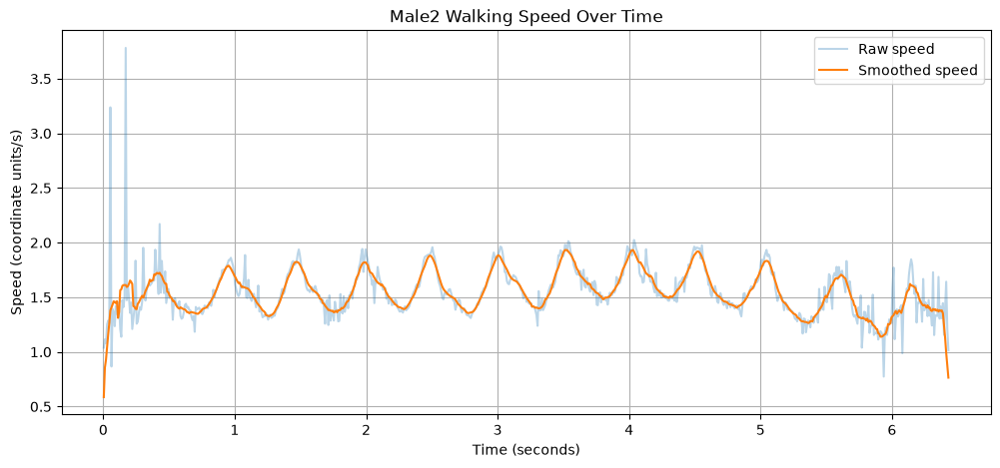

In [37]:
import numpy as np
import matplotlib.pyplot as plt

# Load root translation
with np.load(male2_motion_path, allow_pickle=True) as data:
    male2_trans = data["trans"].astype(np.float64)
    male2_fps = float(np.asarray(data["mocap_framerate"]).squeeze())

# Horizontal coordinates
male2_xy = male2_trans[:, :2]

# Frame-to-frame displacement
male2_displacement = np.diff(male2_xy, axis=0)

male2_step_distance = np.linalg.norm(
    male2_displacement, axis=1
)

# Instantaneous speed
male2_speed = male2_step_distance * male2_fps

# Average speed
male2_duration = (len(male2_trans) - 1) / male2_fps

male2_path_length = male2_step_distance.sum()

male2_net_distance = np.linalg.norm(
    male2_xy[-1] - male2_xy[0]
)

male2_avg_speed = male2_path_length / male2_duration

print("MALE2 WALKING SPEED ANALYSIS")
print("-" * 40)

print("Recording:", male2_motion_path.name)
print("Frames:", len(male2_trans))
print("FPS:", male2_fps)
print(f"Duration: {male2_duration:.2f} seconds")
print(f"Horizontal distance: {male2_path_length:.3f}")
print(f"Net displacement: {male2_net_distance:.3f}")
print(f"Average speed: {male2_avg_speed:.3f} units/s")
print(f"Minimum speed: {male2_speed.min():.3f} units/s")
print(f"Maximum speed: {male2_speed.max():.3f} units/s")

# Plot speed
time_axis = (np.arange(len(male2_speed)) + 0.5) / male2_fps

window = max(1, round(male2_fps * 0.1))

smoothed = np.convolve(
    male2_speed,
    np.ones(window) / window,
    mode="same"
)

plt.figure(figsize=(12, 5))

plt.plot(time_axis, male2_speed, alpha=0.3, label="Raw speed")
plt.plot(time_axis, smoothed, label="Smoothed speed")

plt.xlabel("Time (seconds)")
plt.ylabel("Speed (coordinate units/s)")
plt.title("Male2 Walking Speed Over Time")
plt.legend()
plt.grid(True)
plt.show()

In [38]:
import pandas as pd

comparison = pd.DataFrame([
    {
        "Subject": "Female1",
        "Recording": "B3 - walk1",
        "Average speed": 1.064
    },
    {
        "Subject": "Male2",
        "Recording": "B20 - Walk with box",
        "Average speed": male2_avg_speed
    }
])

display(comparison)

difference = male2_avg_speed - 1.064

print(f"Speed difference: {difference:+.3f} units/s")

,Subject,Recording,Average speed
0,Female1,B3 - walk1,1.064000
1,Male2,B20 - Walk with box,1.549437


Speed difference: +0.485 units/s


In [39]:
import numpy as np
import pandas as pd

# Verify reconstructed motion
assert len(male2_poses) == len(male2_joints_all)
assert len(male2_trans) == len(male2_joints_all)

# Window configuration
window_seconds = 2
overlap_seconds = 1

window_frames = round(window_seconds * male2_fps)
stride = round((window_seconds - overlap_seconds) * male2_fps)

num_frames = len(male2_poses)

starts = list(range(0, num_frames - window_frames + 1, stride))

if not starts:
    raise ValueError("Recording is shorter than one window.")

last_start = num_frames - window_frames

if starts[-1] != last_start:
    starts.append(last_start)

# Output directory
output_dir = (
    project_dir / "data/processed/prototype/windows/male2_B20"
)
output_dir.mkdir(parents=True, exist_ok=True)

records = []

for i, start in enumerate(starts):

    end = start + window_frames

    pose_window = male2_poses[start:end]
    trans_window = male2_trans[start:end]
    joints_window = male2_joints_all[start:end]

    # Root-relative joint coordinates
    relative_joints = (
        joints_window - joints_window[:, 0:1, :]
    )

    # Calculate horizontal speed
    xy = trans_window[:, :2]

    distances = np.linalg.norm(
        np.diff(xy, axis=0), axis=1
    )

    path_length = distances.sum()
    duration = (window_frames - 1) / male2_fps

    avg_speed = path_length / duration

    net_displacement = np.linalg.norm(xy[-1] - xy[0])

    sample_name = f"sample_{i+1:03d}.npz"

    np.savez_compressed(
        output_dir / sample_name,
        poses=pose_window,
        trans=trans_window,
        joints=joints_window,
        joints_root_relative=relative_joints,
        betas=male2_betas[:16],
        fps=np.float32(male2_fps),
        speed_xy_units_per_s=np.float32(avg_speed),
        source_file=np.array(male2_motion_path.name),
        start_frame=np.int32(start),
        end_frame_exclusive=np.int32(end)
    )

    records.append({
        "sample": sample_name,
        "subject": "Male2",
        "source_file": male2_motion_path.name,
        "start_frame": start,
        "end_frame": end,
        "frames": window_frames,
        "duration_seconds": duration,
        "speed_xy_units_per_s": avg_speed,
        "path_length": path_length,
        "net_displacement": net_displacement
    })

# Save manifest
male2_manifest = pd.DataFrame(records)

male2_manifest.to_csv(
    output_dir / "window_manifest.csv",
    index=False
)

display(male2_manifest)

print("\nTotal Male2 windows:", len(male2_manifest))
print("Saved to:", output_dir)

,sample,subject,source_file,start_frame,end_frame,frames,duration_seconds,speed_xy_units_per_s,path_length,net_displacement
0,sample_001.npz,Male2,B20 - Walk with box_poses.npz,0,240,240,1.991667,1.530303,3.047853,3.036718
1,sample_002.npz,Male2,B20 - Walk with box_poses.npz,120,360,240,1.991667,1.556297,3.099625,3.092108
2,sample_003.npz,Male2,B20 - Walk with box_poses.npz,240,480,240,1.991667,1.606464,3.199541,3.190914
3,sample_004.npz,Male2,B20 - Walk with box_poses.npz,360,600,240,1.991667,1.636015,3.258396,3.249084
4,sample_005.npz,Male2,B20 - Walk with box_poses.npz,480,720,240,1.991667,1.534510,3.056232,3.046387
5,sample_006.npz,Male2,B20 - Walk with box_poses.npz,533,773,240,1.991667,1.484074,2.955781,2.946252



Total Male2 windows: 6
Saved to: /home/sharif/projects/human-motion-latent-directions/data/processed/prototype/windows/male2_B20


In [40]:
import pandas as pd
from pathlib import Path

# Project directories
prototype_dir = project_dir / "data/processed/prototype"
windows_dir = prototype_dir / "windows"

# Load both manifests
female_df = pd.read_csv(windows_dir / "window_manifest.csv")
male_df = pd.read_csv(windows_dir / "male2_B20/window_manifest.csv")

# Identify performers and recordings
female_df["performer"] = "Female1"
male_df["performer"] = "Male2"

female_df["recording_id"] = "Female1_B3"
male_df["recording_id"] = "Male2_B20"

# Store paths to the actual motion samples
female_df["sample_path"] = female_df["sample"].apply(
    lambda x: str(Path("windows") / x)
)

male_df["sample_path"] = male_df["sample"].apply(
    lambda x: str(Path("windows/male2_B20") / x)
)

# Combine
combined_df = pd.concat(
    [female_df, male_df],
    ignore_index=True
)

# Give every sample a unique identifier
combined_df["sample_id"] = [
    f"sample_{i+1:03d}" for i in range(len(combined_df))
]

# Verify that every sample exists
combined_df["file_exists"] = combined_df["sample_path"].apply(
    lambda p: (prototype_dir / p).is_file()
)

assert combined_df["file_exists"].all(), "Some motion files are missing!"

# Save combined manifest
manifest_path = prototype_dir / "combined_manifest.csv"

combined_df.to_csv(manifest_path, index=False)

print("Total prototype samples:", len(combined_df))
print("All motion files found:", combined_df["file_exists"].all())

display(
    combined_df[
        ["sample_id", "performer", "recording_id",
         "start_frame", "end_frame", "speed_xy_units_per_s"]
    ]
)

# Compare speed distributions
print("\nSpeed statistics by recording:")

display(
    combined_df.groupby(
        ["performer", "recording_id"]
    )["speed_xy_units_per_s"].agg(
        ["count", "mean", "min", "max"]
    ).round(4)
)

print("\nSaved:", manifest_path)

Total prototype samples: 13
All motion files found: True


,sample_id,performer,recording_id,start_frame,end_frame,speed_xy_units_per_s
0,sample_001,Female1,Female1_B3,0,240,1.041200
1,sample_002,Female1,Female1_B3,120,360,1.039500
2,sample_003,Female1,Female1_B3,240,480,1.053800
3,sample_004,Female1,Female1_B3,360,600,1.090900
4,sample_005,Female1,Female1_B3,480,720,1.069300
5,sample_006,Female1,Female1_B3,600,840,1.093800
6,sample_007,Female1,Female1_B3,675,915,1.082900
7,sample_008,Male2,Male2_B20,0,240,1.530303
8,sample_009,Male2,Male2_B20,120,360,1.556297
9,sample_010,Male2,Male2_B20,240,480,1.606464



Speed statistics by recording:


,,count,mean,min,max
performer,recording_id,,,,
Female1,Female1_B3,7,1.0673,1.0395,1.0938
Male2,Male2_B20,6,1.5579,1.4841,1.6360



Saved: /home/sharif/projects/human-motion-latent-directions/data/processed/prototype/combined_manifest.csv


Total motion windows: 13

Windows per performer:
performer
Female1    7
Male2      6
dtype: int64

Speed statistics by recording:


,,count,mean,std,min,max
performer,recording_id,,,,,
Female1,Female1_B3,7,1.0673,0.0229,1.0395,1.0938
Male2,Male2_B20,6,1.5579,0.0552,1.4841,1.6360


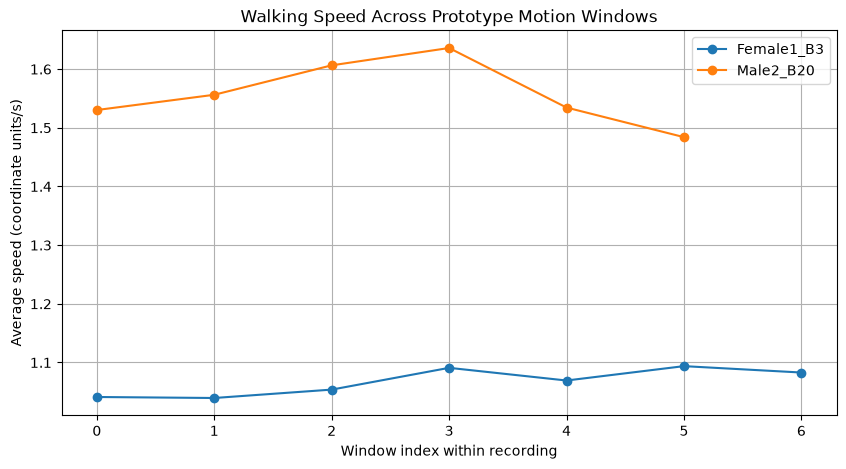

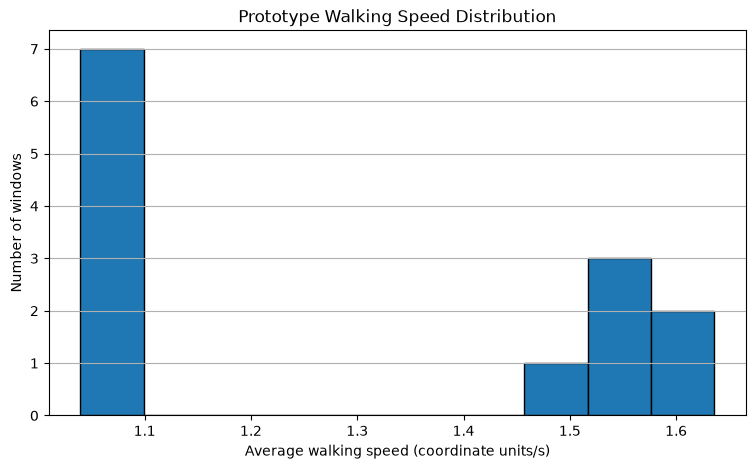

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

# Load combined manifest
manifest_path = (
    project_dir / "data/processed/prototype/combined_manifest.csv"
)

combined_df = pd.read_csv(manifest_path)

# Basic dataset information
print("Total motion windows:", len(combined_df))
print("\nWindows per performer:")
print(combined_df.groupby("performer").size())

# Speed statistics
speed_col = "speed_xy_units_per_s"

print("\nSpeed statistics by recording:")

stats = combined_df.groupby(
    ["performer", "recording_id"]
)[speed_col].agg(
    ["count", "mean", "std", "min", "max"]
)

display(stats.round(4))

# Visualize individual window speeds
plt.figure(figsize=(10, 5))

for recording in combined_df["recording_id"].unique():

    subset = combined_df[
        combined_df["recording_id"] == recording
    ]

    plt.plot(
        range(len(subset)),
        subset[speed_col],
        marker="o",
        label=recording
    )

plt.xlabel("Window index within recording")
plt.ylabel("Average speed (coordinate units/s)")
plt.title("Walking Speed Across Prototype Motion Windows")
plt.legend()
plt.grid(True)
plt.show()

# Overall distribution
plt.figure(figsize=(9, 5))

plt.hist(
    combined_df[speed_col],
    bins=10,
    edgecolor="black"
)

plt.xlabel("Average walking speed (coordinate units/s)")
plt.ylabel("Number of windows")
plt.title("Prototype Walking Speed Distribution")
plt.grid(axis="y")
plt.show()

In [42]:
import numpy as np
import torch
from human_body_prior.body_model.body_model import BodyModel

# Locate Female1 B20 recording
female1_folder = accad_dir / "Female1Walking_c3d"

matches = [
    p for p in female1_folder.glob("*_poses.npz")
    if "B20" in p.name and "box" in p.name.lower()
]

if len(matches) != 1:
    raise ValueError(f"Expected one Female1 B20 recording, found: {matches}")

female1_b20_path = matches[0]

print("Selected:", female1_b20_path.name)

# Load motion parameters
with np.load(female1_b20_path, allow_pickle=True) as data:
    female1_b20_poses = data["poses"].astype(np.float32)
    female1_b20_trans = data["trans"].astype(np.float32)
    female1_b20_betas = data["betas"].astype(np.float32)
    female1_b20_fps = float(
        np.asarray(data["mocap_framerate"]).squeeze()
    )

num_frames = len(female1_b20_poses)

print("Frames:", num_frames)
print("FPS:", female1_b20_fps)
print("Duration:", round(num_frames / female1_b20_fps, 2), "seconds")

# Apply LBS compatibility fix
import human_body_prior.body_model.body_model as bm_module
from smplx.lbs import lbs as smplx_lbs

def compatible_lbs(*args, dtype=None, **kwargs):
    return smplx_lbs(*args, **kwargs)

bm_module.lbs = compatible_lbs

# Load female model
female_model_path = (
    project_dir / "data/body_models/smplh/female/model.npz"
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

female_b20_model = BodyModel(
    bm_path=str(model_path),
    model_type="smplh",
    num_betas=16
).to(device)

female_b20_model.eval()

# Reconstruct all frames in batches
female1_b20_joints = []

batch_size = 32

with torch.no_grad():

    for start in range(0, num_frames, batch_size):

        end = min(start + batch_size, num_frames)

        pose_batch = torch.from_numpy(
            female1_b20_poses[start:end]
        ).to(device)

        trans_batch = torch.from_numpy(
            female1_b20_trans[start:end]
        ).to(device)

        betas_batch = torch.from_numpy(
            np.repeat(
                female1_b20_betas[:16][None, :],
                end - start,
                axis=0
            )
        ).to(device)

        output = female_b20_model(
            root_orient=pose_batch[:, :3],
            pose_body=pose_batch[:, 3:66],
            pose_hand=pose_batch[:, 66:156],
            betas=betas_batch,
            trans=trans_batch
        )

        female1_b20_joints.append(
            output.Jtr.cpu().numpy()
        )

female1_b20_joints = np.concatenate(
    female1_b20_joints, axis=0
)

print("\nReconstruction successful!")
print("3D joints shape:", female1_b20_joints.shape)
print("All joints finite:", np.isfinite(female1_b20_joints).all())

Selected: B20 - walk with box_poses.npz
Frames: 514
FPS: 120.0
Duration: 4.28 seconds

Reconstruction successful!
3D joints shape: (514, 52, 3)
All joints finite: True


In [43]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Load skeletal hierarchy
with np.load(female_model_path, allow_pickle=True) as model:
    kintree = model["kintree_table"]

parents = kintree[0].astype(int)
joint_ids = kintree[1].astype(int)

joint_map = {joint_id: i for i, joint_id in enumerate(joint_ids)}

edges = []

for child, parent_id in enumerate(parents):
    parent = joint_map.get(parent_id)

    if parent is not None and parent != child:
        edges.append((parent, child))

# Select frames for animation
frame_step = max(1, round(female1_b20_fps / 15))
frame_indices = list(range(0, len(female1_b20_joints), frame_step))

if frame_indices[-1] != len(female1_b20_joints) - 1:
    frame_indices.append(len(female1_b20_joints) - 1)

# Fixed axis limits
minimum = female1_b20_joints.min(axis=(0, 1))
maximum = female1_b20_joints.max(axis=(0, 1))

center = (minimum + maximum) / 2
radius = max(np.max(maximum - minimum) / 2 * 1.1, 0.01)

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection="3d")

ax.set_xlim(center[0] - radius, center[0] + radius)
ax.set_ylim(center[1] - radius, center[1] + radius)
ax.set_zlim(center[2] - radius, center[2] + radius)
ax.set_box_aspect((1, 1, 1))

initial = female1_b20_joints[0]

scatter = ax.scatter(
    initial[:, 0], initial[:, 1], initial[:, 2], s=20
)

lines = []

for parent, child in edges:
    line, = ax.plot(
        [initial[parent, 0], initial[child, 0]],
        [initial[parent, 1], initial[child, 1]],
        [initial[parent, 2], initial[child, 2]]
    )
    lines.append(line)


def update(frame_number):

    frame_idx = frame_indices[frame_number]
    joints = female1_b20_joints[frame_idx]

    scatter._offsets3d = (
        joints[:, 0],
        joints[:, 1],
        joints[:, 2]
    )

    for line, (parent, child) in zip(lines, edges):
        line.set_data(
            [joints[parent, 0], joints[child, 0]],
            [joints[parent, 1], joints[child, 1]]
        )
        line.set_3d_properties(
            [joints[parent, 2], joints[child, 2]]
        )

    ax.set_title(
        f"Female1 Walking with Box | "
        f"Time: {frame_idx / female1_b20_fps:.2f}s"
    )

    return [scatter] + lines


animation = FuncAnimation(
    fig,
    update,
    frames=len(frame_indices),
    interval=1000 / 15,
    blit=False
)

plt.close(fig)

display(HTML(animation.to_jshtml(fps=15)))

FEMALE1 B20 SPEED ANALYSIS
----------------------------------------
Recording: B20 - walk with box_poses.npz
Frames: 514
FPS: 120.0
Duration: 4.275 seconds
Horizontal distance: 3.889
Net displacement: 3.859
Average speed: 0.910 units/s
Minimum speed: 0.005 units/s
Maximum speed: 1.557 units/s


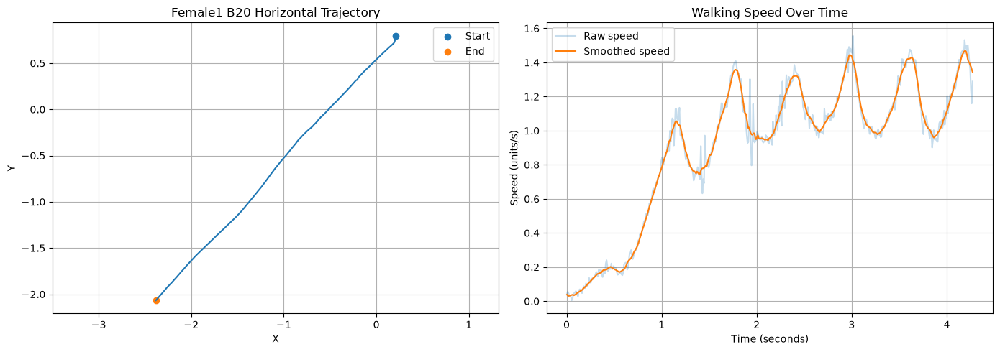

In [44]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Horizontal root translation
xy = female1_b20_trans[:, :2]

# Frame-to-frame displacement
distances = np.linalg.norm(np.diff(xy, axis=0), axis=1)

# Instantaneous speed
speed = distances * female1_b20_fps

# Overall measurements
duration = (len(xy) - 1) / female1_b20_fps
path_length = distances.sum()
net_displacement = np.linalg.norm(xy[-1] - xy[0])

average_speed = path_length / duration

print("FEMALE1 B20 SPEED ANALYSIS")
print("-" * 40)

print("Recording:", female1_b20_path.name)
print("Frames:", len(xy))
print("FPS:", female1_b20_fps)
print(f"Duration: {duration:.3f} seconds")
print(f"Horizontal distance: {path_length:.3f}")
print(f"Net displacement: {net_displacement:.3f}")
print(f"Average speed: {average_speed:.3f} units/s")
print(f"Minimum speed: {speed.min():.3f} units/s")
print(f"Maximum speed: {speed.max():.3f} units/s")

# Smooth speed for visualization
window = max(1, round(female1_b20_fps * 0.1))

smoothed_speed = (
    pd.Series(speed)
    .rolling(window=window, center=True, min_periods=1)
    .mean()
)

time_axis = (np.arange(len(speed)) + 0.5) / female1_b20_fps

# Plot trajectory and speed
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(xy[:, 0], xy[:, 1])
axes[0].scatter(*xy[0], label="Start")
axes[0].scatter(*xy[-1], label="End")
axes[0].set_title("Female1 B20 Horizontal Trajectory")
axes[0].set_xlabel("X")
axes[0].set_ylabel("Y")
axes[0].axis("equal")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(time_axis, speed, alpha=0.25, label="Raw speed")
axes[1].plot(time_axis, smoothed_speed, label="Smoothed speed")
axes[1].set_title("Walking Speed Over Time")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Speed (units/s)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [45]:
import numpy as np
import pandas as pd

# Window configuration
window_frames = int(2 * female1_b20_fps)
stride = int(1 * female1_b20_fps)

num_frames = len(female1_b20_poses)

starts = list(range(
    0, num_frames - window_frames + 1, stride
))

# Include final window to cover the end of the recording
last_start = num_frames - window_frames

if starts[-1] != last_start:
    starts.append(last_start)

# Output directory
output_dir = (
    project_dir / "data/processed/prototype/windows/female1_B20"
)

output_dir.mkdir(parents=True, exist_ok=True)

records = []

for i, start in enumerate(starts):

    end = start + window_frames

    # Extract motion window
    pose_window = female1_b20_poses[start:end]
    trans_window = female1_b20_trans[start:end]
    joints_window = female1_b20_joints[start:end]

    # Root-relative joint coordinates
    relative_joints = (
        joints_window - joints_window[:, 0:1, :]
    )

    # Calculate average horizontal speed
    xy = trans_window[:, :2]

    distances = np.linalg.norm(
        np.diff(xy, axis=0), axis=1
    )

    path_length = distances.sum()
    duration = (window_frames - 1) / female1_b20_fps

    avg_speed = path_length / duration

    net_displacement = np.linalg.norm(
        xy[-1] - xy[0]
    )

    # Save sample
    sample_name = f"sample_{i+1:03d}.npz"

    np.savez_compressed(
        output_dir / sample_name,
        poses=pose_window,
        trans=trans_window,
        joints=joints_window,
        joints_root_relative=relative_joints,
        betas=female1_b20_betas[:16],
        fps=np.float32(female1_b20_fps),
        speed_xy_units_per_s=np.float32(avg_speed),
        source_file=np.array(female1_b20_path.name),
        start_frame=np.int32(start),
        end_frame_exclusive=np.int32(end)
    )

    records.append({
        "sample": sample_name,
        "subject": "Female1",
        "source_file": female1_b20_path.name,
        "start_frame": start,
        "end_frame": end,
        "frames": window_frames,
        "duration_seconds": duration,
        "speed_xy_units_per_s": avg_speed,
        "path_length": path_length,
        "net_displacement": net_displacement
    })

# Create manifest
female1_b20_manifest = pd.DataFrame(records)

female1_b20_manifest.to_csv(
    output_dir / "window_manifest.csv",
    index=False
)

display(female1_b20_manifest)

print("\nTotal windows:", len(female1_b20_manifest))
print("Saved to:", output_dir)

,sample,subject,source_file,start_frame,end_frame,frames,duration_seconds,speed_xy_units_per_s,path_length,net_displacement
0,sample_001.npz,Female1,B20 - walk with box_poses.npz,0,240,240,1.991667,0.621537,1.237894,1.216351
1,sample_002.npz,Female1,B20 - walk with box_poses.npz,120,360,240,1.991667,1.060740,2.112640,2.099452
2,sample_003.npz,Female1,B20 - walk with box_poses.npz,240,480,240,1.991667,1.138083,2.266683,2.258448
3,sample_004.npz,Female1,B20 - walk with box_poses.npz,274,514,240,1.991667,1.184301,2.358733,2.353822



Total windows: 4
Saved to: /home/sharif/projects/human-motion-latent-directions/data/processed/prototype/windows/female1_B20


In [46]:
import pandas as pd
from pathlib import Path

prototype_dir = project_dir / "data/processed/prototype"
windows_dir = prototype_dir / "windows"

# Define our three recordings
recordings = [
    {
        "performer": "Female1",
        "recording_id": "Female1_B3",
        "manifest": windows_dir / "window_manifest.csv",
        "folder": Path("windows")
    },
    {
        "performer": "Male2",
        "recording_id": "Male2_B20",
        "manifest": windows_dir / "male2_B20/window_manifest.csv",
        "folder": Path("windows/male2_B20")
    },
    {
        "performer": "Female1",
        "recording_id": "Female1_B20",
        "manifest": windows_dir / "female1_B20/window_manifest.csv",
        "folder": Path("windows/female1_B20")
    }
]

all_samples = []

for recording in recordings:

    df = pd.read_csv(recording["manifest"])

    df["performer"] = recording["performer"]
    df["recording_id"] = recording["recording_id"]

    df["sample_path"] = df["sample"].apply(
        lambda name: str(recording["folder"] / name)
    )

    all_samples.append(df)

# Combine all recordings
combined_df = pd.concat(all_samples, ignore_index=True)

# Unique sample IDs
combined_df["sample_id"] = [
    f"sample_{i+1:03d}" for i in range(len(combined_df))
]

# Verify files exist
combined_df["file_exists"] = combined_df["sample_path"].apply(
    lambda path: (prototype_dir / path).is_file()
)

assert combined_df["file_exists"].all()

# Save combined manifest
combined_df.to_csv(
    prototype_dir / "combined_manifest.csv",
    index=False
)

print("Total motion windows:", len(combined_df))
print("All files exist:", combined_df["file_exists"].all())

display(
    combined_df[
        ["sample_id", "performer", "recording_id",
         "start_frame", "end_frame", "speed_xy_units_per_s"]
    ]
)

Total motion windows: 17
All files exist: True


,sample_id,performer,recording_id,start_frame,end_frame,speed_xy_units_per_s
0,sample_001,Female1,Female1_B3,0,240,1.041200
1,sample_002,Female1,Female1_B3,120,360,1.039500
2,sample_003,Female1,Female1_B3,240,480,1.053800
3,sample_004,Female1,Female1_B3,360,600,1.090900
4,sample_005,Female1,Female1_B3,480,720,1.069300
5,sample_006,Female1,Female1_B3,600,840,1.093800
6,sample_007,Female1,Female1_B3,675,915,1.082900
7,sample_008,Male2,Male2_B20,0,240,1.530303
8,sample_009,Male2,Male2_B20,120,360,1.556297
9,sample_010,Male2,Male2_B20,240,480,1.606464


In [47]:
import numpy as np
import pandas as pd

validation_results = []

for _, row in combined_df.iterrows():

    file_path = prototype_dir / row["sample_path"]

    with np.load(file_path, allow_pickle=True) as data:

        poses = data["poses"]
        trans = data["trans"]
        joints = data["joints"]
        relative_joints = data["joints_root_relative"]

        fps = float(data["fps"])
        speed = float(data["speed_xy_units_per_s"])

        checks = {
            "240 frames": poses.shape == (240, 156),
            "Translation shape": trans.shape == (240, 3),
            "Joint shape": joints.shape == (240, 52, 3),
            "Relative joint shape": relative_joints.shape == (240, 52, 3),
            "Finite poses": np.isfinite(poses).all(),
            "Finite translation": np.isfinite(trans).all(),
            "Finite joints": np.isfinite(joints).all(),
            "Valid FPS": fps > 0,
            "Speed matches manifest": np.isclose(
                speed,
                row["speed_xy_units_per_s"],
                atol=1e-4
            )
        }

        validation_results.append({
            "sample_id": row["sample_id"],
            "performer": row["performer"],
            "fps": fps,
            "speed": speed,
            "all_checks_passed": all(checks.values()),
            "failed_checks": [
                name for name, passed in checks.items() if not passed
            ]
        })

validation_df = pd.DataFrame(validation_results)

display(validation_df)

print("\nTotal samples:", len(validation_df))
print("Passed:", validation_df["all_checks_passed"].sum())
print("Failed:", (~validation_df["all_checks_passed"]).sum())

assert validation_df["all_checks_passed"].all(), \
    "Some samples failed validation!"

,sample_id,performer,fps,speed,all_checks_passed,failed_checks
0,sample_001,Female1,120.0,1.041238,True,[]
1,sample_002,Female1,120.0,1.039459,True,[]
2,sample_003,Female1,120.0,1.053773,True,[]
3,sample_004,Female1,120.0,1.090947,True,[]
4,sample_005,Female1,120.0,1.069291,True,[]
5,sample_006,Female1,120.0,1.093792,True,[]
6,sample_007,Female1,120.0,1.082915,True,[]
7,sample_008,Male2,120.0,1.530303,True,[]
8,sample_009,Male2,120.0,1.556297,True,[]
9,sample_010,Male2,120.0,1.606464,True,[]



Total samples: 17
Passed: 17
Failed: 0


In [48]:
# preparaing data as model input 

import numpy as np
import pandas as pd

# Configuration
target_fps = 30
downsample_factor = 4

X_list = []
y_list = []

metadata = []

for _, row in combined_df.iterrows():

    sample_path = prototype_dir / row["sample_path"]

    with np.load(sample_path, allow_pickle=True) as data:

        joints = data["joints_root_relative"].astype(np.float32)

        fps = float(data["fps"])
        speed = float(data["speed_xy_units_per_s"])

    # Verify downsampling factor
    factor = round(fps / target_fps)

    if not np.isclose(fps / factor, target_fps):
        raise ValueError(f"Unexpected FPS: {fps}")

    # Downsample 120 FPS -> 30 FPS
    joints_downsampled = joints[::factor]

    # Flatten 52 joints × 3 coordinates = 156 features
    features = joints_downsampled.reshape(
        joints_downsampled.shape[0], -1
    )

    if features.shape != (60, 156):
        raise ValueError(
            f"Unexpected input shape: {features.shape}"
        )

    X_list.append(features)
    y_list.append(speed)

    metadata.append({
        "sample_id": row["sample_id"],
        "performer": row["performer"],
        "recording_id": row["recording_id"],
        "source_file": row["source_file"],
        "speed": speed
    })

# Convert lists into NumPy arrays
X_raw = np.stack(X_list).astype(np.float32)
y_speed = np.array(y_list, dtype=np.float32)

# Normalize each feature using dataset-wide statistics
feature_mean = X_raw.mean(axis=(0, 1), keepdims=True)
feature_std = X_raw.std(axis=(0, 1), keepdims=True)

# Avoid division by zero
feature_std[feature_std < 1e-6] = 1.0

X = (X_raw - feature_mean) / feature_std

# Verify
print("Raw input shape:", X_raw.shape)
print("Normalized input shape:", X.shape)
print("Speed labels shape:", y_speed.shape)

print("All inputs finite:", np.isfinite(X).all())
print("All labels finite:", np.isfinite(y_speed).all())

# Save processed model inputs
input_dir = prototype_dir / "model_inputs"
input_dir.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    input_dir / "walking_dataset.npz",
    X=X,
    X_raw=X_raw,
    y_speed=y_speed,
    feature_mean=feature_mean,
    feature_std=feature_std,
    target_fps=np.float32(target_fps)
)

metadata_df = pd.DataFrame(metadata)

metadata_df.to_csv(
    input_dir / "metadata.csv",
    index=False
)

print("\nModel input dataset saved successfully!")
print("Location:", input_dir)

Raw input shape: (17, 60, 156)
Normalized input shape: (17, 60, 156)
Speed labels shape: (17,)
All inputs finite: True
All labels finite: True

Model input dataset saved successfully!
Location: /home/sharif/projects/human-motion-latent-directions/data/processed/prototype/model_inputs


## Proposed Sequence Autoencoder

| Stage | Shape / Details | Purpose |
| :--- | :--- | :--- |
| Input motion sequence | <span style="font-size: 1.2em;">**(60, 156)**</span> | Input motion sequence |
| Temporal encoder | <span style="font-size: 1.2em;">**Temporal encoder**</span> | Learn spatial and temporal motion patterns |
| Latent vector | <span style="font-size: 1.2em;">**8 dimensions**</span> | Compact motion representation |
| Temporal decoder | <span style="font-size: 1.2em;">**Temporal decoder**</span> | Reconstruct the original sequence |
| Reconstructed motion | <span style="font-size: 1.2em;">**(60, 156)**</span> | Reconstructed motion |

## Small GRU-Based Sequence Autoencoder

<span style="font-size: 1.2em;">Input tensor:</span>

$$X \in \mathbb{R}^{60 \times 156}$$

| Stage | Shape / Spec | Purpose |
| :--- | :--- | :--- |
| Input | <span style="font-size: 1.2em;">**60 × 156**</span> | One motion sequence |
| GRU Encoder | <span style="font-size: 1.2em;">**Hidden dimension: 32**</span> | Encodes temporal motion sequence |
| Latent vector z | <span style="font-size: 1.2em;">**4 dimensions**</span> | Compact latent representation |
| GRU Decoder | <span style="font-size: 1.2em;">**Decodes from z**</span> | Reconstructs the motion sequence |
| Output | <span style="font-size: 1.2em;">**60 × 156**</span> | Reconstructed motion |

Gated Recurrent Unit-GRU

It is a type of recurrent neural network (RNN) designed to process sequential data.

human motion is sequential.

Walking is not just one pose. It is a series of poses over time.

For example:

Frame 1 → Frame 2 → Frame 3 → Frame 4 → ...

A GRU processes these frames in sequence and maintains a hidden state that carries information from earlier frames.

In [49]:
# Defining the model /Model Architecture

import torch
import torch.nn as nn

class MotionAutoencoder(nn.Module):

    def __init__(
        self,
        input_dim=156,
        hidden_dim=32,
        latent_dim=4
    ):
        super().__init__()

        # Encoder
        self.encoder = nn.GRU(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.to_latent = nn.Linear(
            hidden_dim,
            latent_dim
        )

        # Decoder
        self.latent_to_hidden = nn.Linear(
            latent_dim,
            hidden_dim
        )

        self.decoder = nn.GRU(
            input_size=latent_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.output_layer = nn.Linear(
            hidden_dim,
            input_dim
        )

    def forward(self, x):

        # Encode motion
        _, hidden = self.encoder(x)

        z = self.to_latent(hidden[-1])

        # Repeat latent vector across time
        sequence_length = x.shape[1]

        decoder_input = z.unsqueeze(1).expand(
            -1, sequence_length, -1
        )

        initial_hidden = torch.tanh(
            self.latent_to_hidden(z)
        ).unsqueeze(0)

        # Decode motion
        decoded, _ = self.decoder(
            decoder_input,
            initial_hidden
        )

        reconstructed = self.output_layer(decoded)

        return reconstructed, z

# forward-pass test or model sanity check

In [52]:
# Select device and Initialize and test the architecture
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Convert our existing dataset to PyTorch
X_tensor = torch.from_numpy(X).float().to(device)

# Initialize model
model = MotionAutoencoder(
    input_dim=156,
    hidden_dim=32,
    latent_dim=4
).to(device)

# Test forward pass
model.eval()

with torch.no_grad():
    reconstructed, latent = model(X_tensor)

print("Device:", device)
print("Input shape:", X_tensor.shape)
print("Reconstructed shape:", reconstructed.shape)
print("Latent shape:", latent.shape)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

print(
    "Initial reconstruction MSE:",
    nn.functional.mse_loss(reconstructed, X_tensor).item()
)

Device: cuda
Input shape: torch.Size([17, 60, 156])
Reconstructed shape: torch.Size([17, 60, 156])
Latent shape: torch.Size([17, 4])
Trainable parameters: 27328
Initial reconstruction MSE: 0.9948279857635498


## Training Configuration

| Parameter | Value |
| :--- | :--- |
| Training samples | <span style="font-size: 1.2em;">**17**</span> |
| Input dimensions | <span style="font-size: 1.2em;">**156**</span> |
| Sequence length | <span style="font-size: 1.2em;">**60 frames**</span> |
| Latent dimensions | <span style="font-size: 1.2em;">**4**</span> |
| Optimizer | <span style="font-size: 1.2em;">**Adam**</span> |
| Learning rate | <span style="font-size: 1.2em;">**0.001**</span> |
| Epochs | <span style="font-size: 1.2em;">**300**</span> |
| Loss function | <span style="font-size: 1.2em;">**MSE**</span> |

Starting Motion Autoencoder Training
Epoch  50/300 | Reconstruction MSE: 0.371066
Epoch 100/300 | Reconstruction MSE: 0.284928
Epoch 150/300 | Reconstruction MSE: 0.280428
Epoch 200/300 | Reconstruction MSE: 0.278205
Epoch 250/300 | Reconstruction MSE: 0.275700
Epoch 300/300 | Reconstruction MSE: 0.272399

TRAINING SUMMARY
Initial MSE: 0.998272
Final MSE:   0.272322
Loss reduction: 72.72%
Latent shape: (17, 4)
Device: cuda


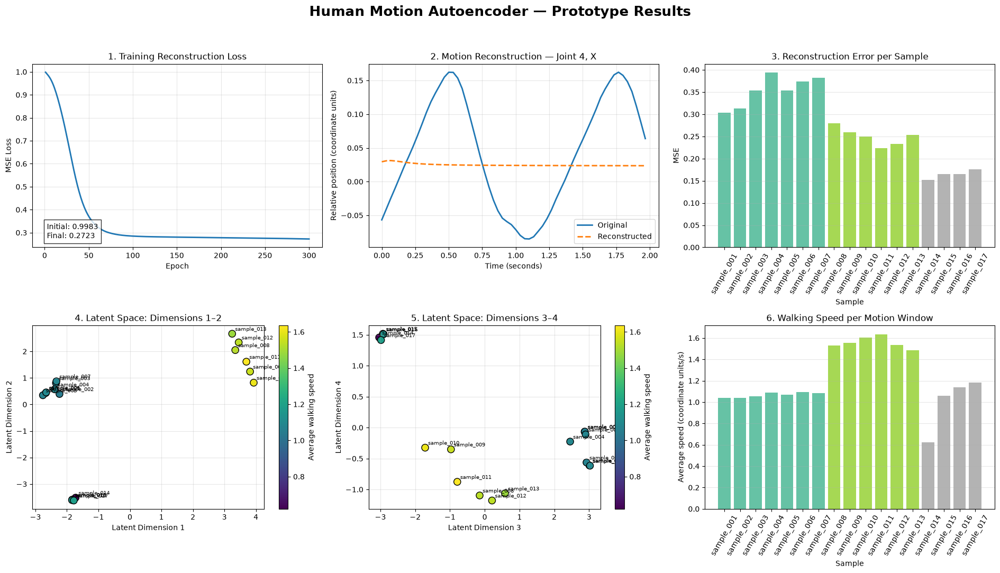


Dashboard saved to:
/home/sharif/projects/human-motion-latent-directions/data/processed/prototype/figures/autoencoder_training_dashboard.png

Trained model checkpoint saved successfully!


In [56]:
# TRAIN THE MODEL 

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ==========================================
# 1. REPRODUCIBILITY AND MODEL INITIALIZATION
# ==========================================

torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Start with a fresh model
model = MotionAutoencoder(
    input_dim=156,
    hidden_dim=32,
    latent_dim=4
).to(device)

X_tensor = torch.from_numpy(X).float().to(device)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 300

# ==========================================
# 2. INITIAL RECONSTRUCTION LOSS
# ==========================================

model.eval()

with torch.no_grad():
    initial_reconstruction, _ = model(X_tensor)

    initial_loss = criterion(
        initial_reconstruction,
        X_tensor
    ).item()

# ==========================================
# 3. TRAINING
# ==========================================

loss_history = []

print("Starting Motion Autoencoder Training")
print("=" * 45)

for epoch in range(epochs):

    model.train()

    optimizer.zero_grad(set_to_none=True)

    reconstructed, latent = model(X_tensor)

    loss = criterion(reconstructed, X_tensor)

    loss.backward()

    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )

    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 50 == 0:
        print(
            f"Epoch {epoch + 1:3d}/{epochs} | "
            f"Reconstruction MSE: {loss.item():.6f}"
        )

# ==========================================
# 4. FINAL EVALUATION
# ==========================================

model.eval()

with torch.no_grad():

    reconstructed_tensor, latent_tensor = model(X_tensor)

    final_loss = criterion(
        reconstructed_tensor,
        X_tensor
    ).item()

    reconstructed_norm = reconstructed_tensor.cpu().numpy()
    latent_values = latent_tensor.cpu().numpy()

# Convert reconstruction back to original feature scale
mean = np.asarray(feature_mean).reshape(1, 1, -1)
std = np.asarray(feature_std).reshape(1, 1, -1)

reconstructed_raw = (
    reconstructed_norm * std + mean
)

# Per-sample reconstruction error
per_sample_mse = np.mean(
    (X - reconstructed_norm) ** 2,
    axis=(1, 2)
)

# ==========================================
# 5. TRAINING SUMMARY
# ==========================================

reduction = (
    (initial_loss - final_loss) / initial_loss
) * 100

print("\nTRAINING SUMMARY")
print("=" * 45)
print(f"Initial MSE: {initial_loss:.6f}")
print(f"Final MSE:   {final_loss:.6f}")
print(f"Loss reduction: {reduction:.2f}%")
print("Latent shape:", latent_values.shape)
print("Device:", device)

# ==========================================
# 6. PRESENTATION DASHBOARD
# ==========================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(19, 11)
)

fig.suptitle(
    "Human Motion Autoencoder — Prototype Results",
    fontsize=19,
    fontweight="bold"
)

# ------------------------------------------
# PLOT 1: TRAINING LOSS
# ------------------------------------------

ax = axes[0, 0]

ax.plot(
    range(1, epochs + 1),
    loss_history,
    linewidth=2
)

ax.set_title("1. Training Reconstruction Loss")
ax.set_xlabel("Epoch")
ax.set_ylabel("MSE Loss")
ax.grid(alpha=0.3)

ax.text(
    0.05, 0.05,
    f"Initial: {initial_loss:.4f}\nFinal: {final_loss:.4f}",
    transform=ax.transAxes,
    bbox=dict(facecolor="white", alpha=0.8)
)

# ------------------------------------------
# PLOT 2: ORIGINAL VS RECONSTRUCTED MOTION
# ------------------------------------------

ax = axes[0, 1]

sample_idx = 2
joint_idx = 4
coordinate_idx = 0

feature_idx = joint_idx * 3 + coordinate_idx

time_axis = np.arange(60) / 30

ax.plot(
    time_axis,
    X_raw[sample_idx, :, feature_idx],
    label="Original",
    linewidth=2
)

ax.plot(
    time_axis,
    reconstructed_raw[sample_idx, :, feature_idx],
    "--",
    label="Reconstructed",
    linewidth=2
)

ax.set_title(f"2. Motion Reconstruction — Joint {joint_idx}, X")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Relative position (coordinate units)")
ax.legend()
ax.grid(alpha=0.3)

# ------------------------------------------
# PLOT 3: RECONSTRUCTION ERROR PER SAMPLE
# ------------------------------------------

ax = axes[0, 2]

sample_ids = combined_df["sample_id"].astype(str)

recordings = combined_df["recording_id"].tolist()

unique_recordings = list(dict.fromkeys(recordings))

palette = plt.cm.Set2(
    np.linspace(0, 1, len(unique_recordings))
)

recording_colors = dict(
    zip(unique_recordings, palette)
)

bar_colors = [
    recording_colors[r] for r in recordings
]

ax.bar(
    sample_ids,
    per_sample_mse,
    color=bar_colors
)

ax.set_title("3. Reconstruction Error per Sample")
ax.set_xlabel("Sample")
ax.set_ylabel("MSE")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=0.3)

# ------------------------------------------
# PLOT 4: LATENT DIMENSIONS 1 AND 2
# ------------------------------------------

ax = axes[1, 0]

scatter = ax.scatter(
    latent_values[:, 0],
    latent_values[:, 1],
    c=y_speed,
    cmap="viridis",
    s=90,
    edgecolors="black"
)

for i, sample_id in enumerate(sample_ids):
    ax.annotate(
        sample_id,
        (latent_values[i, 0], latent_values[i, 1]),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points"
    )

fig.colorbar(
    scatter,
    ax=ax,
    label="Average walking speed"
)

ax.set_title("4. Latent Space: Dimensions 1–2")
ax.set_xlabel("Latent Dimension 1")
ax.set_ylabel("Latent Dimension 2")
ax.grid(alpha=0.3)

# ------------------------------------------
# PLOT 5: LATENT DIMENSIONS 3 AND 4
# ------------------------------------------

ax = axes[1, 1]

scatter2 = ax.scatter(
    latent_values[:, 2],
    latent_values[:, 3],
    c=y_speed,
    cmap="viridis",
    s=90,
    edgecolors="black"
)

for i, sample_id in enumerate(sample_ids):
    ax.annotate(
        sample_id,
        (latent_values[i, 2], latent_values[i, 3]),
        fontsize=7,
        xytext=(4, 4),
        textcoords="offset points"
    )

fig.colorbar(
    scatter2,
    ax=ax,
    label="Average walking speed"
)

ax.set_title("5. Latent Space: Dimensions 3–4")
ax.set_xlabel("Latent Dimension 3")
ax.set_ylabel("Latent Dimension 4")
ax.grid(alpha=0.3)

# ------------------------------------------
# PLOT 6: WALKING SPEED PER SAMPLE
# ------------------------------------------

ax = axes[1, 2]

ax.bar(
    sample_ids,
    y_speed,
    color=bar_colors
)

ax.set_title("6. Walking Speed per Motion Window")
ax.set_xlabel("Sample")
ax.set_ylabel("Average speed (coordinate units/s)")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="y", alpha=0.3)

# ------------------------------------------
# FINALIZE DASHBOARD
# ------------------------------------------

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Save presentation-quality figure
figure_dir = prototype_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

dashboard_path = (
    figure_dir / "autoencoder_training_dashboard.png"
)

plt.savefig(
    dashboard_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("\nDashboard saved to:")
print(dashboard_path)

# ==========================================
# 7. SAVE TRAINED MODEL
# ==========================================

checkpoint_dir = prototype_dir / "checkpoints"
checkpoint_dir.mkdir(parents=True, exist_ok=True)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "input_dim": 156,
        "hidden_dim": 32,
        "latent_dim": 4,
        "target_fps": 30,
        "feature_mean": feature_mean,
        "feature_std": feature_std,
        "initial_mse": initial_loss,
        "final_mse": final_loss,
        "loss_history": loss_history
    },
    checkpoint_dir / "motion_autoencoder.pt"
)

print("\nTrained model checkpoint saved successfully!")

# Extract latent vectors and discover the direction

one walking sample has this latent representation:
\[
z=[z_1,z_2,z_3,z_4]
\]

We want to create a new latent representation by moving one unit along our discovered direction.

We calculate:
\[
z_{\text{new}}=z+d
\]

Where \(d\) is our normalized direction.

So the new coordinates become:
\[
\begin{aligned}
z_{1,\text{new}} &= z_1+0.6775\\
z_{2,\text{new}} &= z_2-0.5349\\
z_{3,\text{new}} &= z_3+0.4187\\
z_{4,\text{new}} &= z_4-0.2820
\end{aligned}
\]


We are changing all four numbers simultaneously.

We are not changing only the first dimension.

We are moving in one specific direction through the four-dimensional latent space.

According to our regression model, this movement increases predicted walking speed.

Latent representation: (17, 4)
Speed labels: (17,)

LATENT DIRECTION ANALYSIS
Regression coefficients: [ 0.15218429 -0.12014176  0.09404838 -0.06335303]
Regression intercept: 1.220037499247501
Normalized direction: [ 0.67752787 -0.53487381  0.41870551 -0.28204911]
Training R²: 0.8296
Correlation with direction: 0.9108
Latent dimension 1 correlation: 0.8907
Latent dimension 2 correlation: 0.6156
Latent dimension 3 correlation: -0.1467
Latent dimension 4 correlation: -0.5958


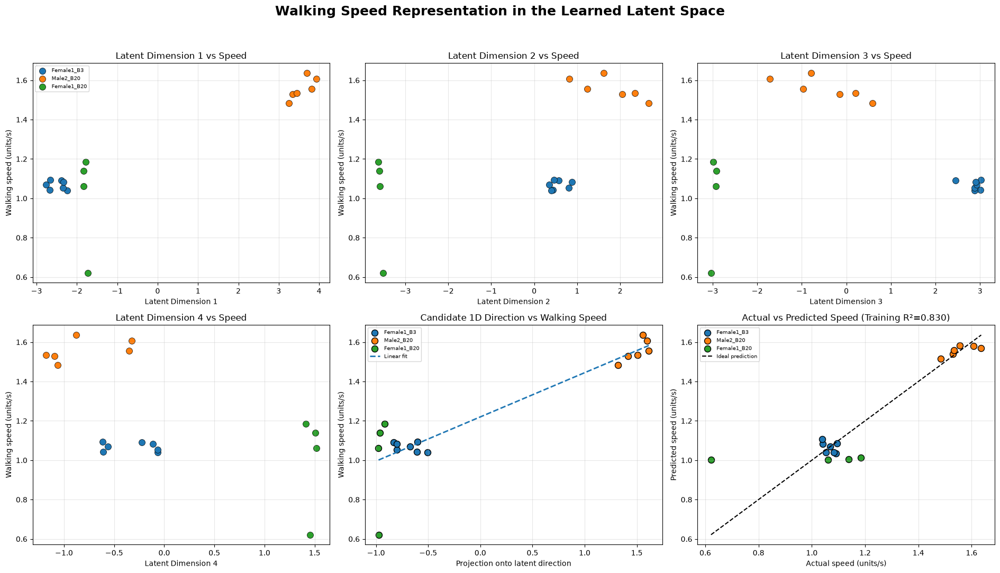


Saved latent analysis and direction successfully.


In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. EXTRACT LATENT REPRESENTATIONS
# ==========================================

model.eval()

with torch.no_grad():
    _, latent_tensor = model(X_tensor)

Z = latent_tensor.cpu().numpy()
y = np.asarray(y_speed).reshape(-1)

assert Z.shape == (17, 4)
assert len(y) == len(Z)

print("Latent representation:", Z.shape)
print("Speed labels:", y.shape)

# ==========================================
# 2. FIT LINEAR REGRESSION
# ==========================================

# Include intercept
A = np.column_stack([Z, np.ones(len(Z))])

# Least-squares regression
coefficients, residuals, rank, singular_values = np.linalg.lstsq(
    A, y, rcond=None
)

w = coefficients[:4]
bias = coefficients[4]

# Predicted speed
predicted_speed = A @ coefficients

# R-squared (training data only)
ss_res = np.sum((y - predicted_speed) ** 2)
ss_total = np.sum((y - y.mean()) ** 2)

r2 = 1 - ss_res / ss_total

# ==========================================
# 3. DISCOVER CANDIDATE 1D DIRECTION
# ==========================================

w_norm = np.linalg.norm(w)

if w_norm < 1e-10:
    raise ValueError("Regression direction is nearly zero.")

direction = w / w_norm

# Projection of every latent vector onto direction
projection = Z @ direction

print("\nLATENT DIRECTION ANALYSIS")
print("=" * 45)

print("Regression coefficients:", w)
print("Regression intercept:", bias)
print("Normalized direction:", direction)
print("Training R²:", round(r2, 4))
print("Correlation with direction:", round(
    np.corrcoef(projection, y)[0, 1], 4
))

# Individual latent dimension correlations
for i in range(4):
    corr = np.corrcoef(Z[:, i], y)[0, 1]
    print(f"Latent dimension {i+1} correlation: {corr:.4f}")

# ==========================================
# 4. PREPARE PRESENTATION DATA
# ==========================================

sample_ids = combined_df["sample_id"].astype(str).tolist()
recordings = combined_df["recording_id"].tolist()

unique_recordings = list(dict.fromkeys(recordings))

palette = plt.cm.Set2(
    np.linspace(0, 1, len(unique_recordings))
)

recording_colors = dict(zip(unique_recordings, palette))

colors = [recording_colors[r] for r in recordings]

# ==========================================
# 5. CREATE SIX-PLOT DASHBOARD
# ==========================================

fig, axes = plt.subplots(2, 3, figsize=(19, 11))

fig.suptitle(
    "Walking Speed Representation in the Learned Latent Space",
    fontsize=18,
    fontweight="bold"
)

# Plot 1-4: Each latent dimension against walking speed

for i in range(4):

    ax = axes.flat[i]

    for recording in unique_recordings:

        indices = [
            j for j, r in enumerate(recordings)
            if r == recording
        ]

        ax.scatter(
            Z[indices, i],
            y[indices],
            s=75,
            label=recording,
            edgecolors="black",
            linewidths=0.5
        )

    ax.set_title(f"Latent Dimension {i+1} vs Speed")
    ax.set_xlabel(f"Latent Dimension {i+1}")
    ax.set_ylabel("Walking speed (units/s)")
    ax.grid(alpha=0.3)

    if i == 0:
        ax.legend(fontsize=7)

# Plot 5: Candidate direction versus speed

ax = axes[1, 1]

for recording in unique_recordings:

    indices = [
        j for j, r in enumerate(recordings)
        if r == recording
    ]

    ax.scatter(
        projection[indices],
        y[indices],
        s=75,
        label=recording,
        edgecolors="black"
    )

# Regression line
x_line = np.linspace(projection.min(), projection.max(), 100)

y_line = w_norm * x_line + bias

ax.plot(x_line, y_line, "--", linewidth=2, label="Linear fit")

ax.set_title("Candidate 1D Direction vs Walking Speed")
ax.set_xlabel("Projection onto latent direction")
ax.set_ylabel("Walking speed (units/s)")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)

# Plot 6: Actual versus predicted speed

ax = axes[1, 2]

for recording in unique_recordings:

    indices = [
        j for j, r in enumerate(recordings)
        if r == recording
    ]

    ax.scatter(
        y[indices],
        predicted_speed[indices],
        s=75,
        label=recording,
        edgecolors="black"
    )

lower = min(y.min(), predicted_speed.min())
upper = max(y.max(), predicted_speed.max())

ax.plot(
    [lower, upper],
    [lower, upper],
    "k--",
    label="Ideal prediction"
)

ax.set_title(f"Actual vs Predicted Speed (Training R²={r2:.3f})")
ax.set_xlabel("Actual speed (units/s)")
ax.set_ylabel("Predicted speed (units/s)")
ax.legend(fontsize=7)
ax.grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# ==========================================
# 6. SAVE RESULTS
# ==========================================

figure_dir = prototype_dir / "figures"
figure_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figure_dir / "latent_speed_analysis.png",
    dpi=250,
    bbox_inches="tight"
)

plt.show()

# Save latent analysis
latent_df = pd.DataFrame(Z, columns=[
    "z1", "z2", "z3", "z4"
])

latent_df.insert(0, "sample_id", sample_ids)
latent_df["actual_speed"] = y
latent_df["predicted_speed"] = predicted_speed
latent_df["latent_projection"] = projection

latent_df.to_csv(
    prototype_dir / "latent_speed_analysis.csv",
    index=False
)

np.savez_compressed(
    prototype_dir / "latent_direction.npz",
    direction=direction,
    coefficients=w,
    intercept=bias,
    latent_vectors=Z,
    projection=projection
)

print("\nSaved latent analysis and direction successfully.")

## Manipulate the Latent Vector

<span style="font-size: 1.2em;">Our original latent vector is:</span>

$$z = (z_1, z_2, z_3, z_4)$$

<span style="font-size: 1.2em;">Our candidate direction is:</span>

$$d = \frac{w}{\|w\|}$$

<span style="font-size: 1.2em;">We will modify the original vector:</span>

$$\boxed{z' = z + \alpha d}$$

<span style="font-size: 1.2em;">Here, $\alpha$ controls how far we move along the direction:</span>

| $\alpha$ Value | Effect |
| :--- | :--- |
| <span style="font-size: 1.2em;">**Negative $\alpha$**</span> | Lower predicted walking speed |
| <span style="font-size: 1.2em;">**Zero**</span> | Original latent representation |
| <span style="font-size: 1.2em;">**Positive $\alpha$**</span> | Higher predicted walking speed |

In [58]:
import numpy as np
import torch
import matplotlib.pyplot as plt

# ==========================================
# 1. SELECT AN ORIGINAL MOTION
# ==========================================

# Select a sample near the median dataset speed
sample_idx = int(np.argmin(np.abs(y - np.median(y))))

z_original = Z[sample_idx]

print("Selected sample:", combined_df.iloc[sample_idx]["sample_id"])
print("Performer:", combined_df.iloc[sample_idx]["performer"])
print("Original measured speed:", y[sample_idx])

# ==========================================
# 2. DEFINE LATENT MOVEMENT
# ==========================================

# Use the spread of training projections to set
# a moderate latent editing range
projection_std = np.std(projection, ddof=1)

alpha_values = np.linspace(
    -1.0, 1.0, 5
) * projection_std

# ==========================================
# 3. FUNCTION TO DECODE A LATENT VECTOR
# ==========================================

def decode_latent(z):

    model.eval()

    device = next(model.parameters()).device

    z_tensor = torch.as_tensor(
        z,
        dtype=torch.float32,
        device=device
    ).reshape(1, 4)

    with torch.no_grad():

        sequence_length = 60

        decoder_input = z_tensor.unsqueeze(1).expand(
            -1, sequence_length, -1
        )

        initial_hidden = torch.tanh(
            model.latent_to_hidden(z_tensor)
        ).unsqueeze(0)

        decoded, _ = model.decoder(
            decoder_input,
            initial_hidden
        )

        output = model.output_layer(decoded)

    return output.squeeze(0).cpu().numpy()


# ==========================================
# 4. MANIPULATE AND DECODE
# ==========================================

edited_sequences = []
edited_latents = []
predicted_speeds = []

for alpha in alpha_values:

    z_modified = z_original + alpha * direction

    # Decode normalized motion
    reconstructed_norm = decode_latent(z_modified)

    # Restore original feature scale
    reconstructed_raw = (
        reconstructed_norm
        * feature_std.reshape(1, 156)
        + feature_mean.reshape(1, 156)
    )

    # Convert 156 features back to 52 joints x 3 coordinates
    reconstructed_joints = reconstructed_raw.reshape(
        60, 52, 3
    )

    # Estimate speed using our fitted linear regression
    estimated_speed = float(
        w @ z_modified + bias
    )

    edited_latents.append(z_modified)
    edited_sequences.append(reconstructed_joints)
    predicted_speeds.append(estimated_speed)


edited_sequences = np.stack(edited_sequences)
edited_latents = np.stack(edited_latents)
predicted_speeds = np.array(predicted_speeds)

print("\nLATENT MANIPULATION RESULTS")
print("=" * 45)

for alpha, speed in zip(alpha_values, predicted_speeds):
    print(
        f"Alpha: {alpha:+.4f} | "
        f"Predicted speed: {speed:.4f}"
    )

print("\nEdited sequence shape:", edited_sequences.shape)

Selected sample: sample_006
Performer: Female1
Original measured speed: 1.093792

LATENT MANIPULATION RESULTS
Alpha: -1.1369 | Predicted speed: 0.8289
Alpha: -0.5685 | Predicted speed: 0.9566
Alpha: +0.0000 | Predicted speed: 1.0842
Alpha: +0.5685 | Predicted speed: 1.2119
Alpha: +1.1369 | Predicted speed: 1.3396

Edited sequence shape: (5, 60, 52, 3)


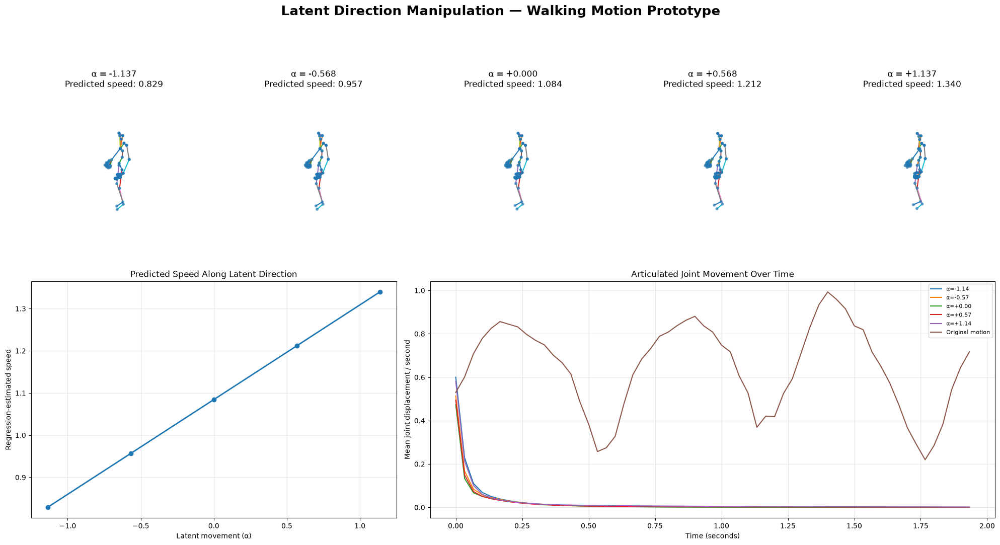

Figure saved: /home/sharif/projects/human-motion-latent-directions/data/processed/prototype/figures/latent_manipulation.png


In [59]:
from matplotlib.gridspec import GridSpec

# Load skeletal hierarchy
with np.load(female_model_path, allow_pickle=True) as model_data:
    kintree = model_data["kintree_table"]

parents = kintree[0].astype(int)
joint_ids = kintree[1].astype(int)

joint_map = {
    joint_id: i for i, joint_id in enumerate(joint_ids)
}

edges = []

for child, parent_id in enumerate(parents):
    parent = joint_map.get(parent_id)

    if parent is not None and parent != child:
        edges.append((parent, child))

# Reconstructed skeletons at middle frame
middle_frame = 30

snapshots = edited_sequences[:, middle_frame]

minimum = snapshots.min(axis=(0, 1))
maximum = snapshots.max(axis=(0, 1))

center = (minimum + maximum) / 2
radius = max(np.max(maximum - minimum) / 2 * 1.15, 0.01)

# Original motion joint sequence
original_joints = X_raw[sample_idx].reshape(60, 52, 3)

# Create dashboard
fig = plt.figure(figsize=(20, 11))

gs = GridSpec(2, 5, figure=fig)

fig.suptitle(
    "Latent Direction Manipulation — Walking Motion Prototype",
    fontsize=19,
    fontweight="bold"
)

# ==========================================
# TOP ROW: FIVE SKELETON SNAPSHOTS
# ==========================================

for i, alpha in enumerate(alpha_values):

    ax = fig.add_subplot(gs[0, i], projection="3d")

    joints = snapshots[i]

    ax.scatter(
        joints[:, 0],
        joints[:, 1],
        joints[:, 2],
        s=12
    )

    for parent, child in edges:
        ax.plot(
            [joints[parent, 0], joints[child, 0]],
            [joints[parent, 1], joints[child, 1]],
            [joints[parent, 2], joints[child, 2]]
        )

    ax.set_xlim(center[0] - radius, center[0] + radius)
    ax.set_ylim(center[1] - radius, center[1] + radius)
    ax.set_zlim(center[2] - radius, center[2] + radius)

    ax.set_box_aspect((1, 1, 1))

    ax.set_title(
        f"α = {alpha:+.3f}\n"
        f"Predicted speed: {predicted_speeds[i]:.3f}"
    )

    ax.set_axis_off()


# ==========================================
# BOTTOM LEFT: SPEED PREDICTION
# ==========================================

ax = fig.add_subplot(gs[1, 0:2])

ax.plot(
    alpha_values,
    predicted_speeds,
    marker="o",
    linewidth=2
)

ax.set_title("Predicted Speed Along Latent Direction")
ax.set_xlabel("Latent movement (α)")
ax.set_ylabel("Regression-estimated speed")
ax.grid(alpha=0.3)


# ==========================================
# BOTTOM RIGHT: ARTICULATED MOTION RATE
# ==========================================

ax = fig.add_subplot(gs[1, 2:5])

# Include original input motion
all_sequences = list(edited_sequences)
all_labels = [f"α={a:+.2f}" for a in alpha_values]

all_sequences.append(original_joints)
all_labels.append("Original motion")

time_axis = np.arange(59) / 30

for sequence, label in zip(all_sequences, all_labels):

    # Average frame-to-frame movement across all joints.
    # This measures articulated movement, NOT global walking speed.
    joint_motion = np.linalg.norm(
        np.diff(sequence, axis=0),
        axis=-1
    ).mean(axis=1) * 30

    ax.plot(
        time_axis,
        joint_motion,
        label=label
    )

ax.set_title("Articulated Joint Movement Over Time")
ax.set_xlabel("Time (seconds)")
ax.set_ylabel("Mean joint displacement / second")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

plt.tight_layout(rect=[0, 0, 1, 0.94])

# Save figure
figure_path = (
    prototype_dir / "figures" / "latent_manipulation.png"
)

plt.savefig(
    figure_path,
    dpi=250,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", figure_path)